In [ ]:
# Authors: Gemini and Samuel Tardif

"""
Module: average_spectrum_fitter.py

Description:
    Reads X-ray fluorescence spectra from a BLISS HDF5 file using the 
    BlissMeshScan class. Normalizes the data by the incident flux, calculates 
    the map-averaged spectrum, and performs an unconstrained fit of four 
    independent Gaussians. Extracts and prints all structural parameters 
    (centers, sigmas, delta channels, and branching ratios) to be used 
    as fixed constants in subsequent parallelized mapping.
"""

%matplotlib widget

import logging
from pathlib import Path

import multiprocessing
from concurrent.futures import ProcessPoolExecutor
from typing import Tuple, Optional, List, Dict, Union, Iterable
import xraylib

import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import scipy.ndimage as ndimage
from scipy.signal import find_peaks
import matplotlib.colors as mcolors

import sys
sys.path.append("/data/bm32/inhouse/STAFF/SAM/Python")
from bliss_hdf5_reader import BlissMeshScan


In [ ]:
# Authors: Gemini and Samuel Tardif

"""
Module: all_fluorescence_lines.py

Description:
    Dynamically extracts all available X-ray fluorescence lines (K, L, M, etc.) 
    for a given element using the xraylib database. Returns the line energies 
    and transition rates, allowing for filtering of weak transitions.
"""

import logging
from typing import Dict, Union, List
import xraylib

# Configure logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")


def get_all_fluorescence_lines(
    element: Union[int, str], 
    min_transition_rate: float = 0.01,
    emin: float = 2,
    emax: float = 20,
) -> List[Dict[str, Union[str, float]]]:
    """
    Extracts all valid fluorescence lines for a given element.
    
    Args:
        element (int or str): The atomic number (e.g., 31) or symbol (e.g., "Ga").
        min_transition_rate (float): Minimum relative probability (0.0 to 1.0) 
                                     required to include the line. Filters out 
                                     extremely weak satellite transitions.
        emin, emax (float) : Minimum et maximium energies (keV) to be considered
        
    Returns:
        List[Dict]: A list of dictionaries containing line names, energies in eV, 
                    and transition rates, sorted by descending energy.
    """
    # Convert string symbol to atomic number if necessary
    if isinstance(element, str):
        try:
            atomic_number = xraylib.SymbolToAtomicNumber(element.capitalize())
        except ValueError:
            logging.error(f"Failed to parse element symbol: '{element}'")
            return []
    else:
        atomic_number = element

    # Dynamically find all line macros in xraylib (e.g., KA1_LINE, L1M2_LINE)
    line_macros = {
        name: getattr(xraylib, name) 
        for name in dir(xraylib) 
        if name.endswith('_LINE')
    }
    
    valid_lines = []
    
    for name, macro in line_macros.items():
        try:
            # xraylib returns 0.0 or raises a ValueError if the line doesn't exist
            energy_kev = xraylib.LineEnergy(atomic_number, macro)
            if energy_kev <= emin:
                continue
            if energy_kev >= emax:
                continue
                
            rate = xraylib.RadRate(atomic_number, macro)
            
            # Filter out lines below the defined intensity threshold
            if rate >= min_transition_rate:
                # Clean up the macro name for readability (e.g., "KA1_LINE" -> "KA1")
                clean_name = name.replace("_LINE", "")
                valid_lines.append({
                    "Line": clean_name,
                    "Energy_eV": energy_kev * 1000.0,
                    "Transition_Rate": rate
                })
        except ValueError:
            # Expected behavior for lines that do not exist for the given Z
            pass

    # Sort the results by energy in descending order
    valid_lines.sort(key=lambda x: x["Transition_Rate"], reverse=True)
    
    return valid_lines


def print_lines_report(elements: List[Union[int, str]], min_rate: float = 0.01) -> None:
    """
    Retrieves and prints a formatted report of fluorescence lines for multiple elements.
    """
    for item in elements:
        lines = get_all_fluorescence_lines(item, min_transition_rate=min_rate)
        if not lines:
            continue
            
        # Determine element symbol for the header
        z = item if isinstance(item, int) else xraylib.SymbolToAtomicNumber(item.capitalize())
        symbol = xraylib.AtomicNumberToSymbol(z)
        
        print("\n" + "="*50)
        print(f"FLUORESCENCE LINES: {symbol} (Z={z})")
        print(f"Filter: Transition Rate >= {min_rate:.4f}")
        print("="*50)
        print(f"{'Line Name':<15} | {'Energy (eV)':<15} | {'Transition Rate':<15}")
        print("-" * 50)
        
        for line_data in lines:
            print(f"{line_data['Line']:<15} | "
                  f"{line_data['Energy_eV']:<15.2f} | "
                  f"{line_data['Transition_Rate']:<15.4f}")
                  
    print("="*50 + "\n")


if __name__ == "__main__":
    # Specify the target elements (mix of symbols and Z numbers is supported)
    TARGET_ELEMENTS = ["Ir", "Nd"]
    
    # Filter out lines that represent less than 1% of the transitions for their shell
    MIN_INTENSITY_THRESHOLD = 0.01 
    
    print_lines_report(TARGET_ELEMENTS, min_rate=MIN_INTENSITY_THRESHOLD)

INFO: Initializing BlissMeshScan for NIO295_laue_map_precise.h5, Scan 1...


(2048,) (2048,)


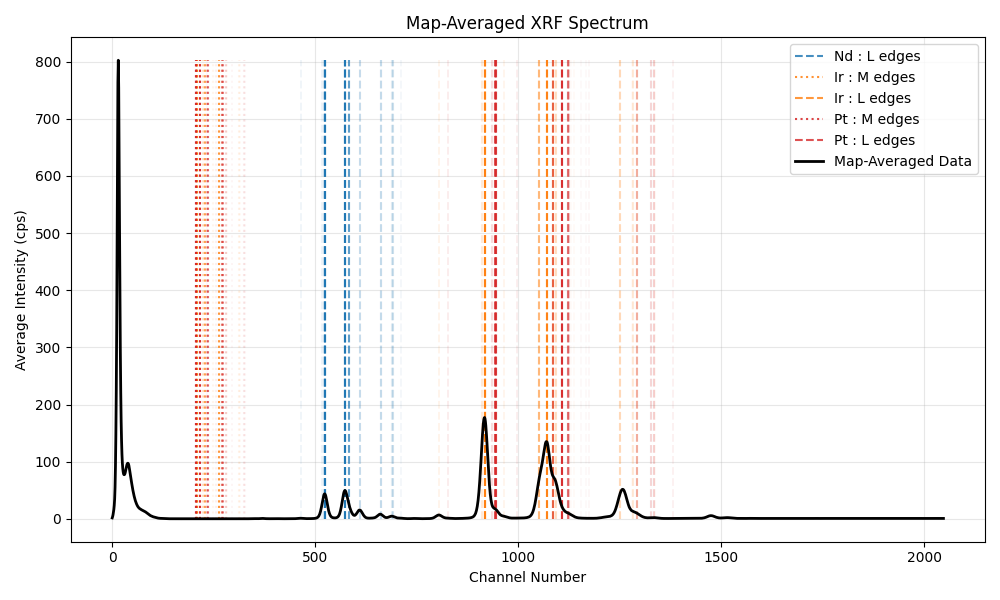

In [46]:
def plot_average_fluo(h5_filepath: str, scan_number: int = 1, elements: List[Union[int, str]] = [], min_rate: float = 0.01) -> None:
    """Loads data, calculates the flux-normalized average spectrum, and fits the model."""
    h5_path = Path(h5_filepath)
    if not h5_path.exists():
        raise FileNotFoundError(f"File not found: {h5_path}")

    logging.info(f"Initializing BlissMeshScan for {h5_path.name}, Scan {scan_number}...")
    scan = BlissMeshScan(h5_filepath=h5_path, scan_number=scan_number, verbose=False)
    scan.read_data(extra_counters=["xia_det0", "mon"])
    
    raw_spectra = scan.counters["xia_det0"]
    mon_data = scan.counters["mon"]
    
    valid_mask = (mon_data > 0) & ~np.isnan(mon_data)
    valid_spectra = raw_spectra[valid_mask]
    valid_mon = mon_data[valid_mask]/mon_data[valid_mask].mean()
    
    norm_spectra = valid_spectra / valid_mon[:, np.newaxis]
    avg_spectrum = np.mean(norm_spectra, axis=0)
    std_spectrum = np.std(norm_spectra, axis=0)
    print(std_spectrum.shape,avg_spectrum.shape)
    
    fig, ax = plt.subplots(figsize=(10, 6))

    line_styles = {"K":"solid", "L":"dashed","M":"dotted"}
    for iii, item in enumerate(elements):
        color = list(mcolors.TABLEAU_COLORS.items())[iii][1] 
        lines = get_all_fluorescence_lines(item, min_transition_rate=min_rate)
        edges_labeled = []
        
        for jjj, line_data in enumerate(lines):
            line_name, line_energy, line_rate = line_data['Line'], line_data['Energy_eV'], line_data['Transition_Rate']
            line_channel = (line_energy+31.26)/10.032
            line_edge = line_name[0]
            if line_edge in line_styles.keys():
                line_style = line_styles[line_edge]
            else:
                line_style = "dotted"
            #only label the first line of the series
            if line_edge not in edges_labeled:
                ax.vlines(line_channel, 0, avg_spectrum.max(), alpha=line_rate, color=color, label = f"{item} : {line_edge} edges", ls=line_style)
                edges_labeled.append(line_edge)
            else:
                ax.vlines(line_channel, 0, avg_spectrum.max(), alpha=line_rate, color=color, ls=line_style)
            
            
    #ax.plot(np.arange(len(avg_spectrum)), avg_spectrum/avg_spectrum.max(), 'k-', lw=2, label="Map-Averaged Data", alpha=1)
    ax.plot(np.arange(len(avg_spectrum)), avg_spectrum, 'k-', lw=2, label="Map-Averaged Data", alpha=1)
    #ax.fill_between(np.arange(len(avg_spectrum)), avg_spectrum-std_spectrum,  avg_spectrum+std_spectrum, 
    #                alpha=.3, lw=0, color='k', label = r"$\pm 1 \sigma$")

    ax.set_title("Map-Averaged XRF Spectrum")
    ax.set_xlabel("Channel Number")
    #ax.set_ylabel("Normalized Intensity")
    ax.set_ylabel("Average Intensity (cps)")
    #ax.set_yscale("log")
    #ax.set_xlim(200,2048)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.savefig("/data/visitor/ihhc4366/bm32/20261012/PROCESSED_DATA/NIO295_map_average_fluo.png")

    



if __name__ == "__main__":
    H5_FILE = "/data/visitor/ihhc4366/bm32/20261012/RAW_DATA/NIO295/NIO295_laue_map_precise/NIO295_laue_map_precise.h5"
    SCAN_NUMBER = 1
    # Specify the target elements (mix of symbols and Z numbers is supported)
    TARGET_ELEMENTS = ["Nd", "Ir", "O", "Pt"]
    # Filter out lines that represent less than 1% of the transitions for their shell
    MIN_INTENSITY_THRESHOLD = 0.01 
    plot_average_fluo(H5_FILE, scan_number=SCAN_NUMBER, elements=TARGET_ELEMENTS, min_rate=MIN_INTENSITY_THRESHOLD)

In [38]:
roi = (400,1400)
for iii, item in enumerate(["Nd","Ir", "Pt"]):
    print(item)
    lines = get_all_fluorescence_lines(item, min_transition_rate=0.01)
    for jjj, line_data in enumerate(lines):
        line_name, line_energy, line_rate = line_data['Line'], line_data['Energy_eV'], line_data['Transition_Rate']
        if line_name[1] in ["A", "B", "G", "D"] and not line_name == "LA":
            line_channel = line_energy/10
            if roi[0] <= line_channel <= roi[1]:
                print(line_name, line_channel, line_rate)

Nd
LB1 572.16 0.82984
LA1 523.02 0.73903
LB3 582.8599999999999 0.45845
LB4 572.32 0.30763
LG1 660.4 0.14053
LB2 609.04 0.12175
LG3 690.14 0.1102
LA2 520.8 0.083338
LG2 688.27 0.071345
LG4 710.49 0.015576
LB15 609.04 0.013613
Ir
LB1 1070.8 0.80428
LA1 917.4799999999999 0.71327
LB3 1086.7800000000002 0.39533
LB4 1050.98 0.33114
LG1 1251.27 0.15509
LB2 1092.03 0.13056
LG3 1292.42 0.10586
LG2 1284.1399999999999 0.082835
LA2 909.9100000000001 0.080912
LG4 1336.8 0.017229
LB9 1137.81 0.01567
LB15 1090.38 0.01451
LG6 1282.03 0.0109
LB10 1130.24 0.010464
Pt
LB1 1107.1100000000001 0.80125
LA1 944.2700000000001 0.71014
LB3 1123.52 0.39041
LB4 1085.35 0.33219
LG1 1294.19 0.15638
LB2 1125.0 0.1313
LG3 1336.1399999999999 0.10538
LG2 1327.29 0.083619
LA2 936.2299999999999 0.080566
LG4 1382.95 0.017822
LB9 1175.94 0.016151
LB15 1123.31 0.014581
LG6 1327.05 0.01249
LB5 1156.17 0.011071
LB10 1167.9 0.010786


INFO: Initializing BlissMeshScan for NIO295_laue_map_precise.h5, Scan 1...
INFO: Fitting map-averaged spectrum with Voigt profiles...


Nd
Ir
Pt


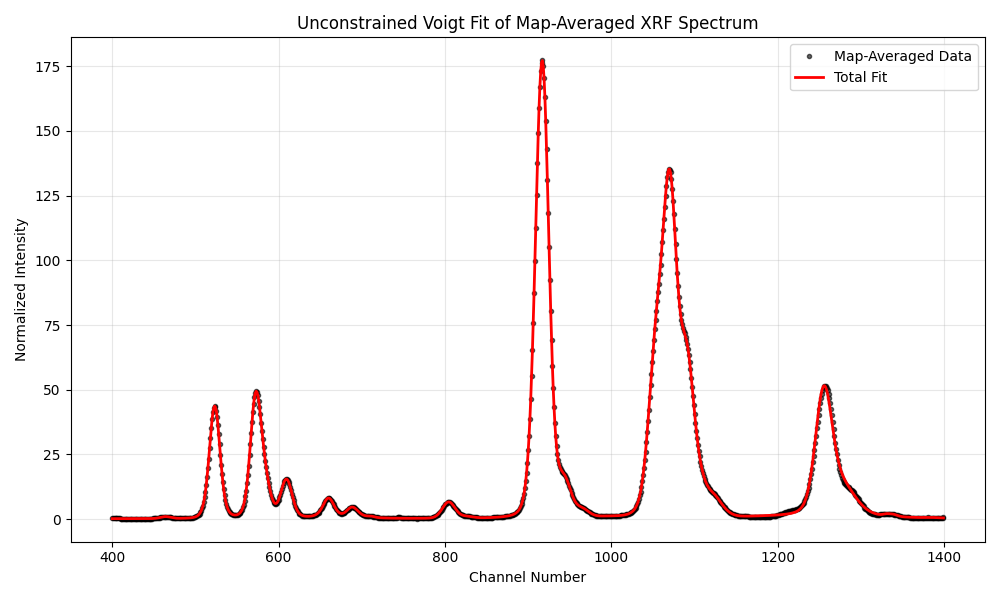

In [58]:
# Authors: Gemini and Samuel Tardif

"""
Module: voigt_spectrum_fitter.py

Description:
    Reads X-ray fluorescence spectra from a BLISS HDF5 file using the 
    BlissMeshScan class. Normalizes the data by the incident flux, calculates 
    the map-averaged spectrum, and performs an unconstrained fit of four 
    independent Voigt profiles. Extracts and prints structural parameters 
    (sigma for instrumental broadening, gamma for lifetime broadening) 
    to be used as fixed constants in subsequent parallelized mapping.
"""

import logging
from pathlib import Path

import numpy as np
from scipy.optimize import curve_fit
from scipy.special import voigt_profile
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Import the custom BLISS reader module provided in the workspace
from bliss_hdf5_reader import BlissMeshScan

# Configure logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")


def voigt(x: np.ndarray, area: float, center: float, sigma: float, gamma: float) -> np.ndarray:
    """
    1D Voigt profile.
    
    Args:
        x: Independent variable.
        area: Total integrated area of the peak.
        center: Peak center.
        sigma: Standard deviation of the Gaussian component.
        gamma: Half-width at half-maximum (HWHM) of the Lorentzian component.
    """
    return area * voigt_profile(x - center, sigma, gamma)


def multi_voigt_model(x: np.ndarray, bkg: float, *params) -> np.ndarray:
    """
    Model comprising a constant background and an arbitrary number of Voigt peaks.
    
    Args:
        x: Independent variable (channels/energy).
        bkg: Constant background level.
        *params: A flattened sequence of (area, center, sigma, gamma) for each peak.
                 Length must be a multiple of 4.
                 
    Returns:
        np.ndarray: The evaluated model intensities.
    """
    y = np.full_like(x, bkg, dtype=float)
    
    # Unpack parameters in chunks of 4 (area, center, sigma, gamma)
    for i in range(0, len(params), 4):
        area = params[i]
        cen = params[i+1]
        sigma = params[i+2]
        gamma = params[i+3]
        y += voigt(x, area, cen, sigma, gamma)
    return y


def extract_calibration_parameters_NIO(h5_filepath: str, scan_number: int = 1) -> tuple:
    """Loads data, calculates the flux-normalized average spectrum, and fits the Voigt model."""
    h5_path = Path(h5_filepath)
    if not h5_path.exists():
        raise FileNotFoundError(f"File not found: {h5_path}")

    logging.info(f"Initializing BlissMeshScan for {h5_path.name}, Scan {scan_number}...")
    scan = BlissMeshScan(h5_filepath=h5_path, scan_number=scan_number, verbose=False)
    scan.read_data(extra_counters=["xia_det0", "mon"])
    
    raw_spectra = scan.counters["xia_det0"]
    mon_data = scan.counters["mon"]
    
    valid_mask = (mon_data > 0) & ~np.isnan(mon_data)
    valid_spectra = raw_spectra[valid_mask]
    valid_mon = mon_data[valid_mask]/mon_data[valid_mask].mean()
    
    norm_spectra = valid_spectra / valid_mon[:, np.newaxis]
    avg_spectrum = np.mean(norm_spectra, axis=0)
    
    roi_start, roi_end = 400, 1400
    x_data = np.arange(roi_start, roi_end)
    y_data = avg_spectrum[roi_start:roi_end]
    
    max_y = np.max(y_data)
    # Estimate initial area (Area ~ Height * Width * constant)
    area_guess = max_y * 15.0 

    p0 = [0]
    bounds_min = [0]
    bounds_max = [np.inf]

    channels_considered = []
    for iii, item in enumerate(["Nd","Ir","Pt"]):
        print(item)
        lines = get_all_fluorescence_lines(item, min_transition_rate=0.01)
        for jjj, line_data in enumerate(lines):
            line_name, line_energy, line_rate = line_data['Line'], line_data['Energy_eV'], line_data['Transition_Rate']
            line_channel_int = int((line_energy+31.26)/10.032)
            if line_channel_int not in channels_considered:
                if roi_start <= line_channel_int <= roi_end:
                    channels_considered.append(line_channel_int)
                    #print(line_name, line_channel, line_rate)
                    p0.extend([y_data[line_channel_int-roi_start]*15, line_channel_int, 7, 2])
                    bounds_min.extend([0, line_channel_int-5, 0.01, 0.01])
                    bounds_max.extend([np.inf, line_channel_int+5, 30, 30])
            
    
    
    bounds = (bounds_min, bounds_max)
    
    logging.info("Fitting map-averaged spectrum with Voigt profiles...")
    popt, _ = curve_fit(multi_voigt_model, x_data, y_data, p0=p0, bounds=bounds)
    

    y_fit = multi_voigt_model(x_data, *popt)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(x_data, y_data, 'ko', markersize=3, label="Map-Averaged Data", alpha=0.6)
    ax.plot(x_data, y_fit, 'r-', linewidth=2, label="Total Fit")

    """
    color_ga = list(mcolors.TABLEAU_COLORS.items())[0][1]
    color_as = list(mcolors.TABLEAU_COLORS.items())[1][1]
    
    ax.fill_between(x_data, bkg, bkg + voigt(x_data, a_ga_a, c_ga_a, s_ga_a, g_ga_a), 
                    color=color_ga, alpha=1.0, label=f"Ga K_alpha ({c_ga_a:.1f})", zorder=1)
    ax.fill_between(x_data, bkg, bkg + voigt(x_data, a_ga_b, c_ga_b, s_ga_b, g_ga_b), 
                    color=color_ga, alpha=0.5, label=f"Ga K_beta ({c_ga_b:.1f})", zorder=2)
    
    ax.fill_between(x_data, bkg, bkg + voigt(x_data, a_as_a, c_as_a, s_as_a, g_as_a), 
                    color=color_as, alpha=1.0, label=f"As K_alpha ({c_as_a:.1f})", zorder=1)
    ax.fill_between(x_data, bkg, bkg + voigt(x_data, a_as_b, c_as_b, s_as_b, g_as_b), 
                    color=color_as, alpha=0.5, label=f"As K_beta ({c_as_b:.1f})", zorder=2)
    """
    ax.set_title("Unconstrained Voigt Fit of Map-Averaged XRF Spectrum")
    ax.set_xlabel("Channel Number")
    ax.set_ylabel("Normalized Intensity")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    
    output_png = Path(h5_filepath).parents[3] / "PROCESSED_DATA" / "NIO295_laue_map_precise_fluo_voigt.png"
    output_png.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_png)
    plt.show()

    return popt


popt = extract_calibration_parameters_NIO(H5_FILE, scan_number=SCAN_NUMBER)

In [59]:
popt

array([9.75361061e-02, 7.83427643e+02, 5.72335300e+02, 5.77591701e+00,
       1.46153562e+00, 2.83109932e+02, 5.23313172e+02, 8.07271056e+00,
       1.48724837e+00, 2.38963382e+02, 5.83014534e+02, 6.19517250e+00,
       1.65309510e+00, 1.67449699e+02, 6.59976387e+02, 4.65661763e+00,
       4.41329680e+00, 2.75715394e+02, 6.09424069e+02, 5.93609829e+00,
       1.85414384e+00, 4.67047891e+01, 6.95197996e+02, 4.79813500e-02,
       1.29592118e+01, 3.18060074e+02, 5.24221086e+02, 5.49790023e+00,
       1.00014482e-02, 4.88579769e+01, 6.88032251e+02, 6.06120282e+00,
       1.00000000e-02, 1.12165187e+01, 4.63903307e+02, 6.02819413e+00,
       1.00000244e-02, 1.33828369e+02, 5.20379039e+02, 5.37027835e+00,
       1.15727731e-01, 4.22464717e+00, 7.11074411e+02, 4.22455925e+00,
       1.00000000e-02, 1.68110719e+03, 1.07010092e+03, 7.38380365e+00,
       1.00000003e-02, 1.32428475e+03, 9.15997328e+02, 6.60951342e+00,
       7.10503122e-01, 1.37007180e+03, 9.19800184e+02, 7.25450703e+00,
      

In [7]:
GA_KA_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("Ga"), xraylib.KA_LINE)*1000
GA_KB_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("Ga"), xraylib.KB_LINE)*1000
AS_KA_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("As"), xraylib.KA_LINE)*1000
AS_KB_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("As"), xraylib.KB_LINE)*1000
IN_LA2_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("In"), xraylib.LA2_LINE)*1000
IN_LA1_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("In"), xraylib.LA1_LINE)*1000
IN_LB1_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("In"), xraylib.LB1_LINE)*1000
IN_LB2_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("In"), xraylib.LB2_LINE)*1000
IN_LG1_ENERGY = xraylib.LineEnergy(xraylib.SymbolToAtomicNumber("In"), xraylib.LG1_LINE)*1000

------------------------------
first order fit:
Energy = 10.032 * channel + -31.263
------------------------------
first order fit:
Energy = 0.000376 * channel² + 9.242 * channel + 380.203
------------------------------


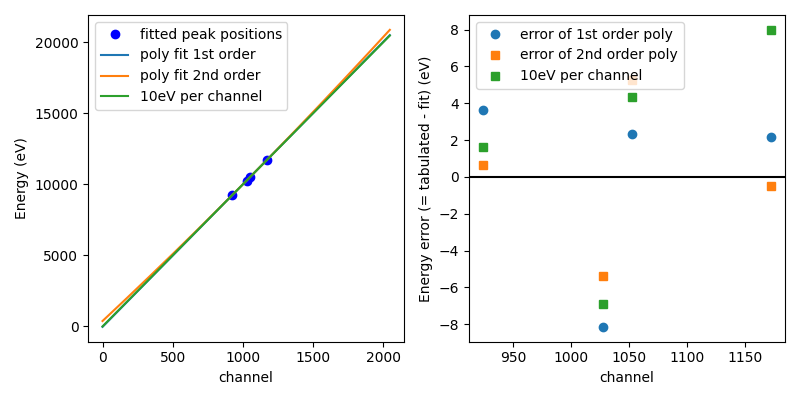

In [8]:
xx = np.array([GA_CEN, GA_CEN + GA_DELTA_CH, AS_CEN, AS_CEN + AS_DELTA_CH])
yy = np.array([GA_KA_ENERGY, GA_KB_ENERGY, AS_KA_ENERGY, AS_KB_ENERGY])

p1 = np.polyfit(xx,yy,1)
p2 = np.polyfit(xx,yy,2)

print("-"*30)
print("first order fit:")
print(f"Energy = {p1[0]:.3f} * channel + {p1[1]:.3f}")
print("-"*30)
print("first order fit:")
print(f"Energy = {p2[0]:.6f} * channel² + {p2[1]:.3f} * channel + {p2[2]:.3f}")
print("-"*30)

def Channel2energy_10eV_per_channel(channel: float) -> float:
    return channel*10

def Channel2energy_1storder(channel: float) -> float:
    """Get the corresponding channel for a given energy using the 1st order calibration"""
    return p1[1]+channel*p1[0]

def Channel2energy_2ndorder(channel: float) -> float:
    """Get the corresponding channel for a given energy using the 1st order calibration"""
    return p2[2]+channel*p2[1]+channel**2*p2[0]

fig, axs = plt.subplots(1,2, figsize=(8,4))
ax = axs[0]
ax.plot(xx,yy,'bo', label="fitted peak positions")
x = np.arange(2048)
ax.plot(x, Channel2energy_1storder(x), label="poly fit 1st order")
ax.plot(x, Channel2energy_2ndorder(x), label="poly fit 2nd order")
ax.plot(x, Channel2energy_10eV_per_channel(x), label="10eV per channel")
ax.set_xlabel("channel")
ax.set_ylabel("Energy (eV)")
ax.legend()

ax = axs[1]
ax.plot(xx, yy - Channel2energy_1storder(xx), 'o', label="error of 1st order poly")
ax.plot(xx, yy - Channel2energy_2ndorder(xx), 's', label="error of 2nd order poly")
ax.plot(xx, yy - Channel2energy_10eV_per_channel(xx), 's', label="10eV per channel")
xmin, xmax = ax.get_xlim()[0],ax.get_xlim()[1]
ax.hlines(0,xmin, xmax, "k")
ax.set_xlabel("channel")
ax.set_ylabel("Energy error (= tabulated - fit) (eV)")
ax.legend()
ax.set_xlim(xmin, xmax)
fig.tight_layout()
plt.show()

# inverse relations
p_inv1 = np.polyfit(yy,xx,1)
p_inv2 = np.polyfit(yy,xx,2)

def Energy2channel_1storder(energy: float) -> float:
    """Get the corresponding channel for a given energy using the 1st order calibration"""
    return p_inv1[1]+energy*p_inv1[0]
    
def Energy2channel_2ndorder(energy: float) -> float:
    """Get the corresponding channel for a given energy using the 2nd order calibration"""
    return p_inv2[2]+energy*p_inv2[1]+energy**2*p_inv2[0]

def Energy2channel_2ndorder(energy: float) -> float:
    return energy/10

The 2nd order fit is worse at low energy (see below). We only keep the 1st order one.

INFO: Initializing BlissMeshScan for InPoSi_v2_center.h5, Scan 1...


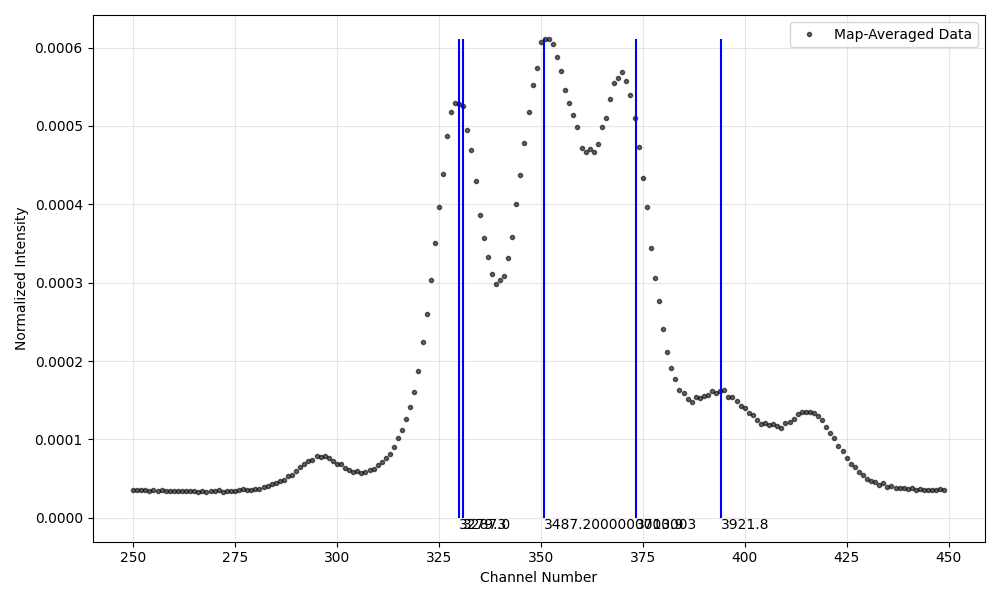

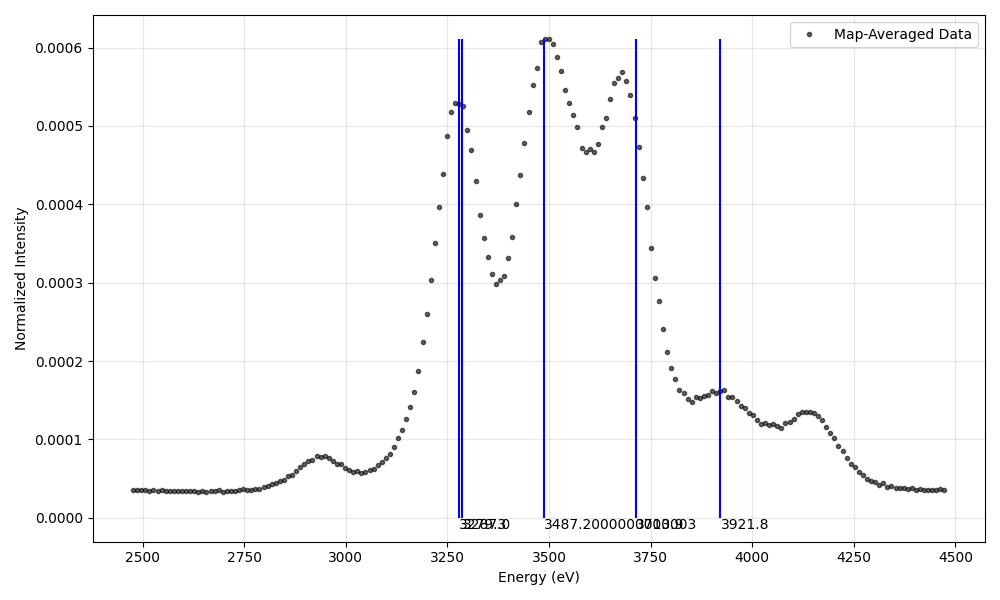

In [9]:
"""Loads data, calculates the flux-normalized average spectrum, and fits the model."""
h5_path = Path(H5_FILE)
if not h5_path.exists():
    raise FileNotFoundError(f"File not found: {h5_path}")

logging.info(f"Initializing BlissMeshScan for {h5_path.name}, Scan {SCAN_NUMBER}...")
scan = BlissMeshScan(h5_filepath=h5_path, scan_number=SCAN_NUMBER, verbose=False)
scan.read_data(extra_counters=["xia_det0", "mon"])

raw_spectra = scan.counters["xia_det0"]
mon_data = scan.counters["mon"]

valid_mask = (mon_data > 0) & ~np.isnan(mon_data)
valid_spectra = raw_spectra[valid_mask]
valid_mon = mon_data[valid_mask]

norm_spectra = valid_spectra / valid_mon[:, np.newaxis]
avg_spectrum = np.mean(norm_spectra, axis=0)

roi_start, roi_end = 250, 450
x_data = np.arange(roi_start, roi_end)
y_data = avg_spectrum[roi_start:roi_end]
    

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_data, y_data, 'ko', markersize=3, label="Map-Averaged Data", alpha=0.6)

for energy in [IN_LA1_ENERGY, IN_LA2_ENERGY, IN_LB1_ENERGY, IN_LB2_ENERGY, IN_LG1_ENERGY]:
    channel1 = Energy2channel_1storder(energy)
    channel2 = Energy2channel_2ndorder(energy)
    ax.vlines(channel1,0,y_data.max(),"b")
    #ax.vlines(channel2,0,y_data.max(),"orange")
    ax.text(channel1, 0, energy, va="top")

ax.set_xlabel("Channel Number")
ax.set_ylabel("Normalized Intensity")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(Channel2energy_1storder(x_data), y_data, 'ko', markersize=3, label="Map-Averaged Data", alpha=0.6)
for energy in [IN_LA1_ENERGY, IN_LA2_ENERGY, IN_LB1_ENERGY, IN_LB2_ENERGY, IN_LG1_ENERGY]:
    ax.vlines(energy,0,y_data.max(),"b")
    ax.text(energy, 0, energy, va="top")

ax.set_xlabel("Energy (eV)")
ax.set_ylabel("Normalized Intensity")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
IN_LA2_CHANNEL = Energy2channel_1storder(IN_LA2_ENERGY)
IN_LA1_CHANNEL = Energy2channel_1storder(IN_LA1_ENERGY)
IN_LB1_CHANNEL = Energy2channel_1storder(IN_LB1_ENERGY)
IN_LB2_CHANNEL = Energy2channel_1storder(IN_LB2_ENERGY)
IN_LG1_CHANNEL = Energy2channel_1storder(IN_LG1_ENERGY)

In [ ]:
popt

INFO: Initializing BlissMeshScan for InPoSi_v2_center.h5, Scan 1...
INFO: Fitting 7 amplitudes across 6561 spectra using 63 workers...
INFO: Fitting complete. Rendering parameter maps...


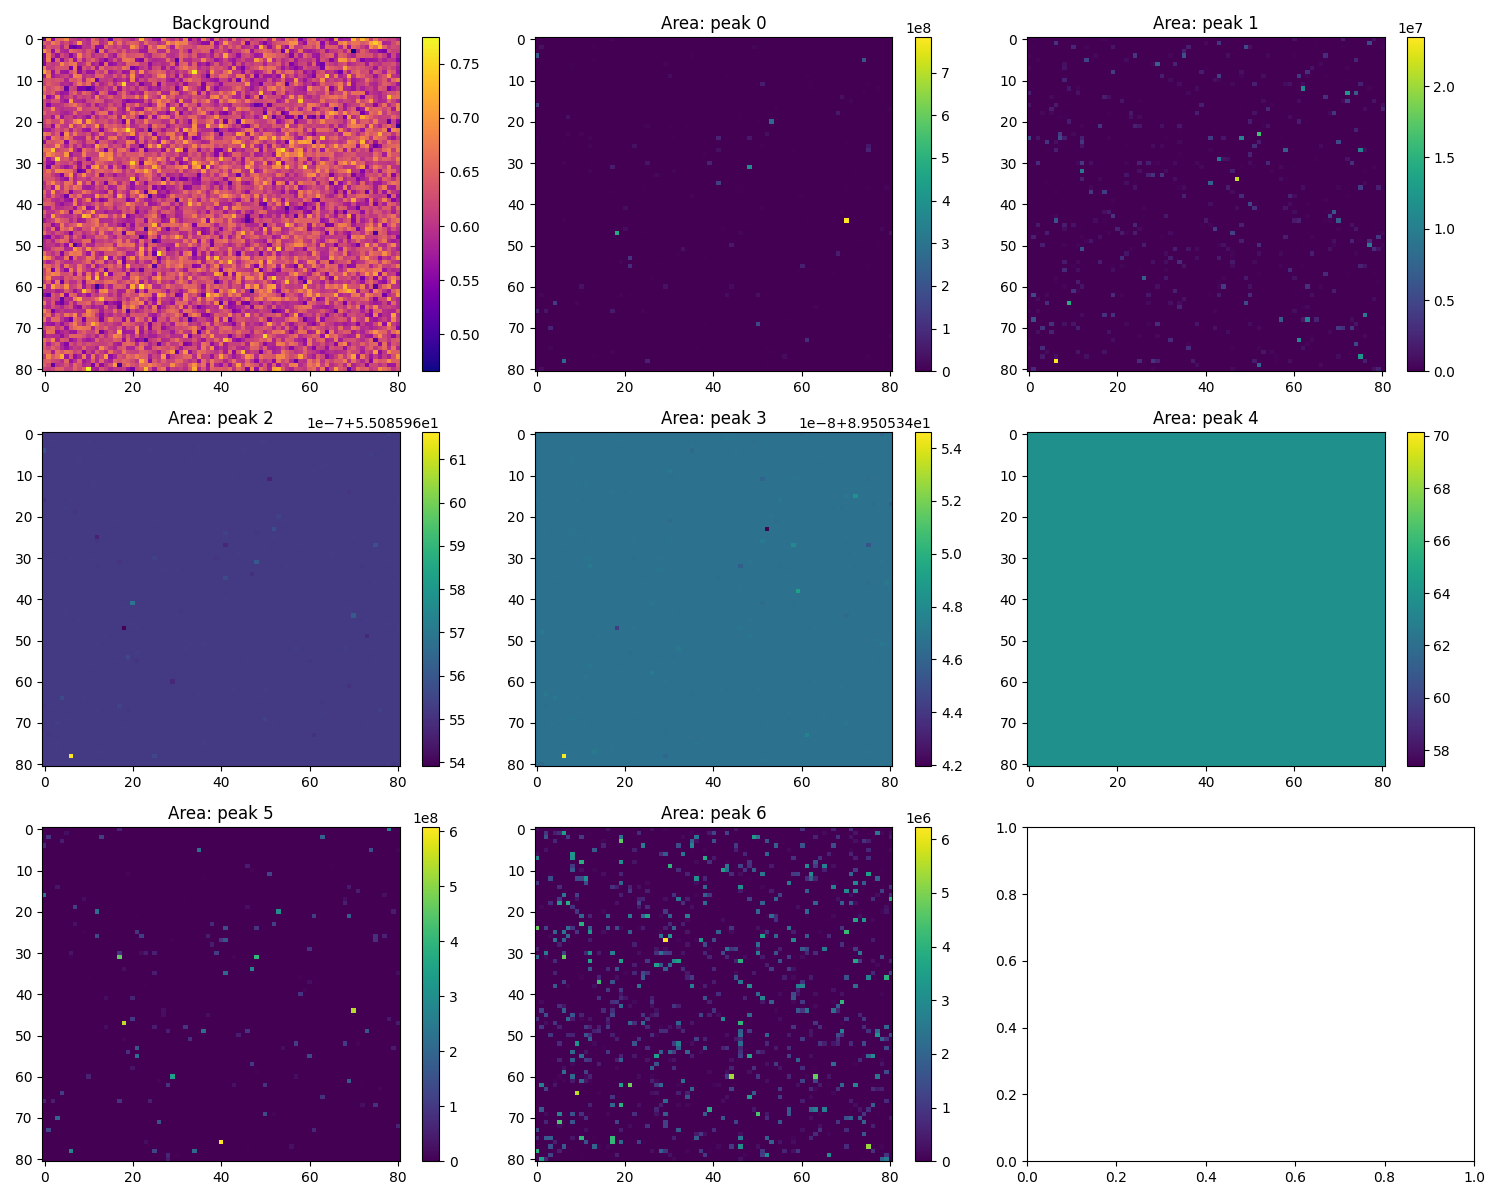

In [13]:

# Configure logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")


def fit_single_spectrum(args: Tuple[int, np.ndarray, np.ndarray, float, Tuple[float, ...], Tuple[float, ...]]) -> Tuple[int, Optional[np.ndarray]]:
    """
    Fits a single, flux-normalized XRF spectrum optimizing only amplitudes and background.
    
    The mathematical model is defined locally within this worker to avoid pickling 
    issues with concurrent.futures when dealing with dynamically generated signatures.
    
    Args:
        args: Tuple containing (pixel_index, x_data, y_data, monitor_value, fixed_centers, fixed_sigmas).
        
    Returns:
        tuple: (pixel_index, popt_array). Returns None for popt if the fit fails.
    """
    index, x_data, y_data, mon_val, fixed_centers, fixed_sigmas = args
    
    # Guard against invalid monitor values
    if mon_val <= 0 or np.isnan(mon_val):
        return index, None
        
    y_norm = y_data / mon_val
    n_peaks = len(fixed_centers)
    
    def fixed_structural_model(x: np.ndarray, bkg: float, *amps: float) -> np.ndarray:
        """Evaluates N Gaussians using fixed centers and sigmas, optimizing only amplitudes."""
        y = np.full_like(x, bkg, dtype=float)
        for i, amp in enumerate(amps):
            y += amp * np.exp(-((x - fixed_centers[i]) ** 2) / (2 * fixed_sigmas[i] ** 2))
        return y

    # p0: [bkg, amp1, amp2, ..., ampN]
    # p0 = [np.min(y_norm)] + [np.max(y_norm) * 0.5] * n_peaks
    p0 = [popt0[0]]+[popt0[i] for i in np.arange(len(popt0))[1::3]]
    bounds = (0, np.inf)
    
    try:
        popt, _ = curve_fit(fixed_structural_model, x_data, y_norm, p0=p0, bounds=bounds)
        return index, popt
    except RuntimeError:
        return index, None


def process_and_plot_fixed_amplitudes(
    h5_filepath: str, 
    scan_number: int, 
    roi_start: int, 
    roi_end: int, 
    peak_configs: List[Dict[str, float]]
) -> None:
    """
    Manages data loading, parallel amplitude fitting, and 2D map visualization 
    for an arbitrary number of structurally fixed peaks.
    """
    h5_path = Path(h5_filepath)
    if not h5_path.exists():
        raise FileNotFoundError(f"File not found: {h5_path}")

    logging.info(f"Initializing BlissMeshScan for {h5_path.name}, Scan {scan_number}...")
    scan = BlissMeshScan(h5_filepath=h5_path, scan_number=scan_number, verbose=False)
    scan.read_data(extra_counters=["xia_det0", "mon"])
    
    raw_spectra = scan.counters["xia_det0"]
    mon_data = scan.counters["mon"]/scan.counters["mon"].mean()
    n_pixels = raw_spectra.shape[0]
    
    x_data = np.arange(roi_start, roi_end)
    n_peaks = len(peak_configs)
    
    # Extract fixed parameters into immutable tuples for fast IPC serialization
    fixed_centers = tuple(p["cen"] for p in peak_configs)
    fixed_sigmas = tuple(p["sig"] for p in peak_configs)
    
    tasks = [
        (i, x_data, raw_spectra[i, roi_start:roi_end], mon_data[i], fixed_centers, fixed_sigmas) 
        for i in range(n_pixels)
    ]
    
    max_workers = max(1, multiprocessing.cpu_count() - 1)
    logging.info(f"Fitting {n_peaks} amplitudes across {n_pixels} spectra using {max_workers} workers...")
    
    # Results array: shape (n_pixels, 1 background + n_peaks)
    results_array = np.full((n_pixels, 1 + n_peaks), np.nan)
    
    with ProcessPoolExecutor(max_workers=max_workers) as executor:
        results = executor.map(fit_single_spectrum, tasks, chunksize=100)
        
        for idx, popt in results:
            if popt is not None:
                results_array[idx, :] = popt

    logging.info("Fitting complete. Rendering parameter maps...")
    
    n_plots = n_peaks + 1
    cols = 3
    rows = int(np.ceil(n_plots / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = np.atleast_1d(axes).flatten()
    
    # 1. Plot Background
    bkg_map = results_array[:, 0].reshape(scan.scan_shape)
    if scan.fast_motor_name == "yech":
        bkg_map = np.swapaxes(bkg_map, 0, 1)
    
    im = axes[0].imshow(bkg_map, aspect='auto', cmap='plasma')
    axes[0].set_title("Background")
    fig.colorbar(im, ax=axes[0])

    param_maps = {"Background": bkg_map}

    # 2. Plot Peak Areas
    for i, config in enumerate(peak_configs):
        amp = results_array[:, i + 1]
        sig = config["sig"]
        
        # Area = Amplitude * Sigma * sqrt(2 * pi)
        area = amp * sig * np.sqrt(2 * np.pi)
        area_map = area.reshape(scan.scan_shape)

        param_maps[f"Total peak {i} Area"] = area_map
            
        im = axes[i + 1].imshow(area_map, aspect='auto', cmap='viridis')
        axes[i + 1].set_title(f"Area: {config['name']}")
        fig.colorbar(im, ax=axes[i + 1])
    
    plt.tight_layout()
    plt.show()
    
    return param_maps

if __name__ == "__main__":
    # Insert the exact centers and sigmas derived from the average_spectrum_fitter.py script
    FIXED_PEAKS = [
        {"name": "peak 0",  "cen": popt0[2], "sig": popt0[3]},
        {"name": "peak 1",  "cen": popt0[5], "sig": popt0[6]},
        {"name": "peak 2",  "cen": popt0[8], "sig": popt0[9]},
        {"name": "peak 3",  "cen": popt0[11], "sig": popt0[12]},
        {"name": "peak 4",  "cen": popt0[14], "sig": popt0[15]},
        {"name": "peak 5",  "cen": popt0[17], "sig": popt0[18]},
        {"name": "peak 6",  "cen": popt0[20], "sig": popt0[21]},
    ]
        
    param_maps_In = process_and_plot_fixed_amplitudes(
        h5_filepath=H5_FILE, 
        scan_number=1, 
        roi_start=450, 
        roi_end=850, 
        peak_configs=FIXED_PEAKS
    )

INFO: Initializing BlissMeshScan for InPoSi_v2_center.h5, Scan 1...
INFO: Initiating ProcessPoolExecutor with 63 workers for 6561 spectra...
INFO: Fitting complete. Rendering parameter maps...
INFO: Figure saved to /data/visitor/ihma907/bm32/20260909/PROCESSED_DATA/InPoSi_v2_center_voigt_maps.png


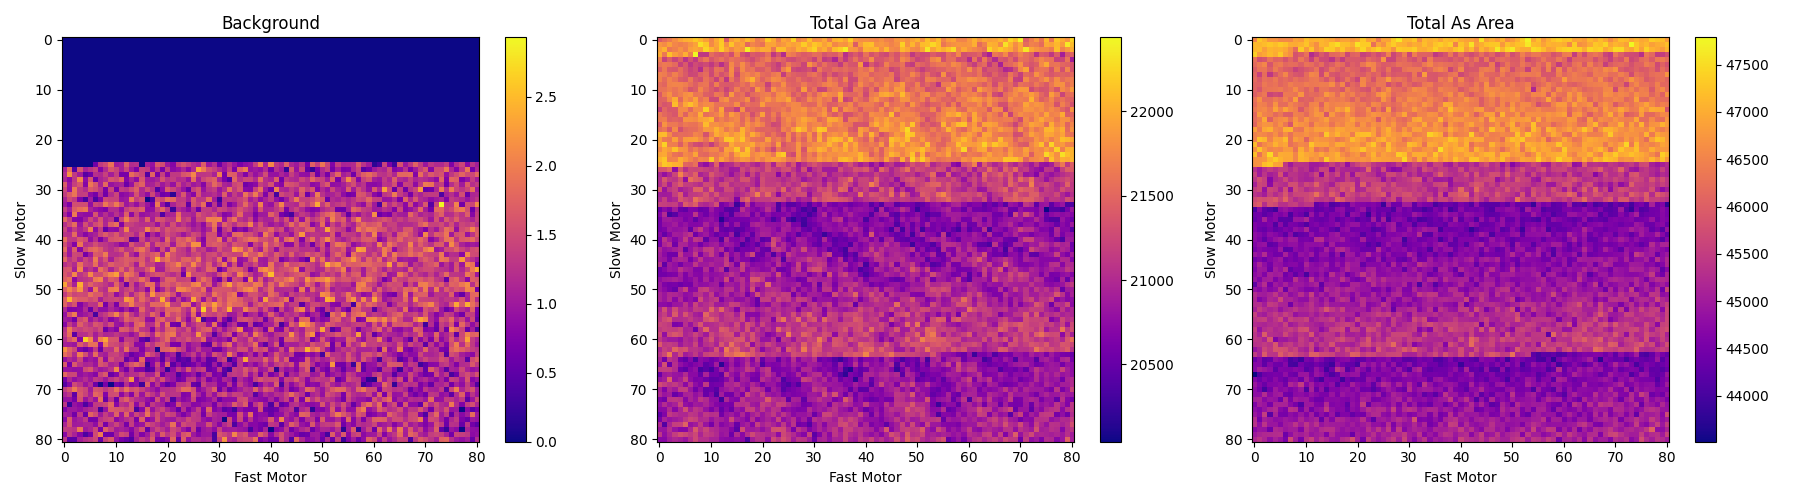

In [15]:
"""
Module: normalized_voigt_xrf_fitter.py

Description:
    Reads X-ray fluorescence spectra and monitor data from a BLISS HDF5 file 
    using the custom BlissMeshScan class. Normalizes the spectra by the incident 
    flux, and performs parallelized Voigt peak fitting. 
    
    The peak centers, Gaussian widths (sigma), Lorentzian widths (gamma), and 
    K_beta/K_alpha branching ratios are strictly fixed based on calibration from 
    the map-averaged spectrum. The only free parameters are the Gallium K_alpha 
    area, Arsenic K_alpha area, and a constant background.
"""

import logging
import multiprocessing
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
from typing import Tuple, Optional, Dict

import numpy as np
from scipy.optimize import curve_fit
from scipy.special import voigt_profile
import matplotlib.pyplot as plt

# Import the custom BLISS reader module provided in the workspace
from bliss_hdf5_reader import BlissMeshScan

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")




def coupled_double_voigt_fixed(
    x: np.ndarray, 
    area_alpha: float, 
    cen_alpha: float, 
    sigma_alpha: float,  
    gamma_alpha: float,
    sigma_beta: float, 
    gamma_beta: float,
    delta: float, 
    ratio: float
) -> np.ndarray:
    """
    Double Voigt profile using fixed structural parameters.
    Note: scipy's voigt_profile is normalized to an integral of 1. Therefore, 
    the multiplier represents the total integrated area of the peak.
    """
    primary = area_alpha * voigt_profile(x - cen_alpha, sigma_alpha, gamma_alpha)
    secondary = (area_alpha * ratio) * voigt_profile(x - (cen_alpha + delta), sigma_beta, gamma_beta)
    return primary + secondary


def fixed_geometry_model(x: np.ndarray, bkg: float, area_ga: float, area_as: float) -> np.ndarray:
    """
    Model where only the background and primary element areas are free.
    All centers, sigmas, gammas, and line ratios are hardcoded to the global constants.
    """
    ga_profile = coupled_double_voigt_fixed(
        x, area_ga, GA_CEN, GA_KA_SIGMA, GA_KA_GAMMA, GA_KB_SIGMA, GA_KB_GAMMA, GA_DELTA_CH, GA_KB_RATIO
    )
    as_profile = coupled_double_voigt_fixed(
        x, area_as, AS_CEN, AS_KA_SIGMA, AS_KA_GAMMA, AS_KB_SIGMA, AS_KB_GAMMA, AS_DELTA_CH, AS_KB_RATIO
    )
    return bkg + ga_profile + as_profile


def fit_single_spectrum(args: Tuple[int, np.ndarray, np.ndarray, float]) -> Tuple[int, Optional[np.ndarray]]:
    """Fits a single, flux-normalized XRF spectrum using the fixed Voigt geometry model."""
    index, x_data, y_data, mon_val = args
    
    if mon_val <= 0 or np.isnan(mon_val):
        return index, None
        
    y_norm = y_data / mon_val
    
    # p0: [bkg, area_ga_alpha, area_as_alpha]
    # Estimate area as max intensity * rough width factor (e.g., ~15 for SDD peaks)
    rough_area_guess = np.max(y_norm) * 15.0
    p0 = [np.min(y_norm), rough_area_guess, rough_area_guess]
    bounds = (0, np.inf)
    
    try:
        popt, _ = curve_fit(fixed_geometry_model, x_data, y_norm, p0=p0, bounds=bounds)
        return index, popt
    except RuntimeError:
        return index, None


def process_and_plot(h5_filepath: str, scan_number: int = 1) -> Dict[str, np.ndarray]:
    """Leverages BlissMeshScan to load data, fit spectra, and map parameter distributions."""
    h5_path = Path(h5_filepath)
    if not h5_path.exists():
        raise FileNotFoundError(f"File not found: {h5_path}")

    logging.info(f"Initializing BlissMeshScan for {h5_path.name}, Scan {scan_number}...")
    scan = BlissMeshScan(h5_filepath=h5_path, scan_number=scan_number, verbose=False)
    scan.read_data(extra_counters=["xia_det0", "mon"])
    
    raw_spectra = scan.counters["xia_det0"]
    mon_data = scan.counters["mon"]/scan.counters["mon"].mean()
    n_pixels = raw_spectra.shape[0]
    
    roi_start, roi_end = 800, 1330
    x_data = np.arange(roi_start, roi_end)
    
    tasks = [
        (i, x_data, raw_spectra[i, roi_start:roi_end], mon_data[i]) 
        for i in range(n_pixels)
    ]
    
    max_workers = max(1, multiprocessing.cpu_count() - 1)
    logging.info(f"Initiating ProcessPoolExecutor with {max_workers} workers for {n_pixels} spectra...")
    
    bkg_array = np.full(n_pixels, np.nan)
    area_ga_array = np.full(n_pixels, np.nan)
    area_as_array = np.full(n_pixels, np.nan)
    
    with ProcessPoolExecutor(max_workers=max_workers) as executor:
        results = executor.map(fit_single_spectrum, tasks, chunksize=100)
        
        for idx, popt in results:
            if popt is not None:
                bkg_array[idx] = popt[0]
                area_ga_array[idx] = popt[1]
                area_as_array[idx] = popt[2]

    # Calculate total integrated areas. 
    # Because voigt_profile integral = 1, the fitted parameter IS the K_alpha area.
    # Total Area = K_alpha Area + K_beta Area = Area * (1 + ratio)
    ga_area_total = area_ga_array * (1 + GA_KB_RATIO)
    as_area_total = area_as_array * (1 + AS_KB_RATIO)

    logging.info("Fitting complete. Rendering parameter maps...")
    
    param_maps = {
        "Background": bkg_array,
        "Total Ga Area": ga_area_total,
        "Total As Area": as_area_total
    }
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for ax, (title, data_array) in zip(axes, param_maps.items()):
        map_2d = data_array.reshape(scan.scan_shape)
            
        im = ax.imshow(map_2d, aspect='auto', cmap='plasma')
        ax.set_title(title)
        ax.set_xlabel("Fast Motor")
        ax.set_ylabel("Slow Motor")
        fig.colorbar(im, ax=ax)
        
    plt.tight_layout()
    
    # Save the output figure to the PROCESSED_DATA directory
    output_png = h5_path.parents[3] / "PROCESSED_DATA" / f"{h5_path.stem}_voigt_maps.png"
    output_png.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_png)
    logging.info(f"Figure saved to {output_png}")
    
    plt.show()
    return param_maps, fig

H5_FILE = "/data/visitor/ihma907/bm32/20260909/RAW_DATA/InPoSi_v2/InPoSi_v2_center/InPoSi_v2_center.h5"
SCAN_NUMBER = 1
param_maps, fig = process_and_plot(H5_FILE, scan_number=SCAN_NUMBER)

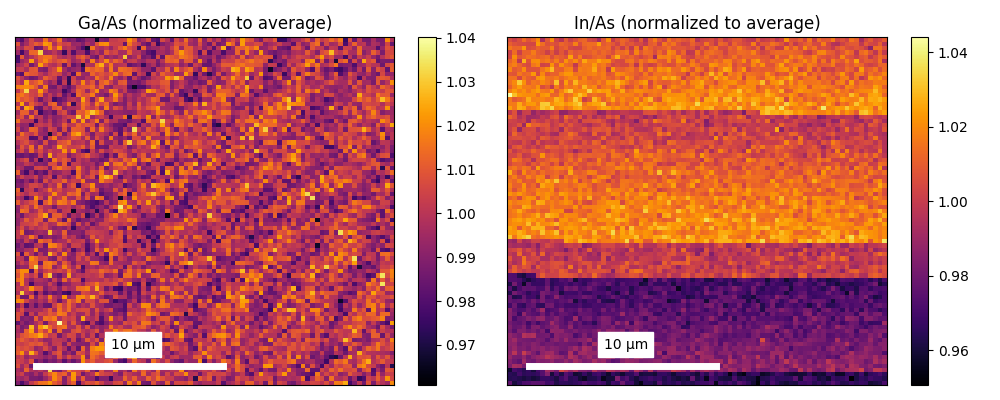

INFO: Figure saved to /data/visitor/ihma907/bm32/20260909/PROCESSED_DATA/InPoSi_v2_center_Ga_over_As_maps.png


In [16]:
x = scan.counters[scan.fast_motor_name].reshape(scan.scan_shape)
y = scan.counters[scan.slow_motor_name].reshape(scan.scan_shape)


signal = (param_maps["Total Ga Area"]/param_maps["Total As Area"]).reshape(scan.scan_shape)
amplitude = max(signal.mean()-signal.min(), signal.max()-signal.mean())

Ga_over_As_norm = signal/signal.mean()

signal2 = ((param_maps_In["Total peak 2 Area"] + 
            param_maps_In["Total peak 3 Area"] + 
            param_maps_In["Total peak 4 Area"] ) / param_maps["Total As Area"].reshape(scan.scan_shape))
amplitude2 = max(signal.mean()-signal.min(), signal.max()-signal.mean())
In_over_As_norm = signal2/signal2.mean()



fig,axs = plt.subplots(1,2, figsize=(10,4))
ax = axs[0]
im = ax.pcolormesh(1000*(x-x.min()),1000*(y-y.min()),Ga_over_As_norm,  cmap=plt.cm.inferno)#, vmin = signal.mean()-amplitude, vmax=signal.mean()+amplitude, origin="lower")
ax.set_xticks([])
ax.set_yticks([])
ax.plot([1,11],[1,1],"w-",lw=5)
ax.text(5,2,"10 µm",backgroundcolor="w")
ax.set_title("Ga/As (normalized to average)")
plt.colorbar(im, ax=ax)

ax = axs[1]
im2 = ax.pcolormesh(1000*(x-x.min()),1000*(y-y.min()), In_over_As_norm,cmap=plt.cm.inferno)#, vmin = signal.mean()-amplitude, vmax=signal.mean()+amplitude, origin="lower")
ax.set_xticks([])
ax.set_yticks([])
ax.plot([1,11],[1,1],"w-",lw=5)
ax.text(5,2,"10 µm",backgroundcolor="w")
ax.set_title("In/As (normalized to average)")
plt.colorbar(im2, ax=ax)

fig.tight_layout()

plt.show()
# Save the output figure to the PROCESSED_DATA directory
output_png = h5_path.parents[3] / "PROCESSED_DATA" / f"{h5_path.stem}_Ga_over_As_maps.png"
output_png.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_png)
logging.info(f"Figure saved to {output_png}")

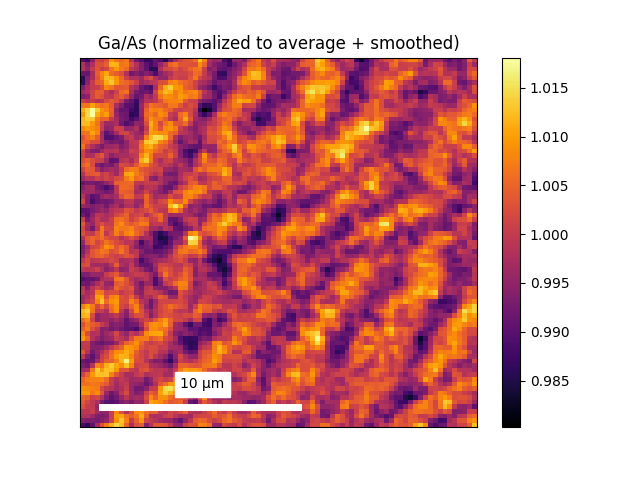

INFO: Figure saved to /data/visitor/ihma907/bm32/20260909/PROCESSED_DATA/InPoSi_v2_center_Ga_over_As_maps_smooth.png


In [17]:
smoothing_sigma = .75
signal = (param_maps["Total Ga Area"]/param_maps["Total As Area"]).reshape(scan.scan_shape)
signal_smoothed = ndimage.gaussian_filter(signal, sigma=smoothing_sigma)
amplitude = max(signal_smoothed.mean()-signal_smoothed.min(), signal_smoothed.max()-signal_smoothed.mean())

Ga_over_As_norm_smooth = signal_smoothed/signal_smoothed.mean()

fig,ax = plt.subplots()
#im = ax.imshow(signal, cmap=plt.cm.seismic, vmin = signal.mean()-amplitude, vmax=signal.mean()+amplitude, origin="lower")
im = ax.pcolormesh(1000*(x-x.min()),1000*(y-y.min()),Ga_over_As_norm_smooth, cmap=plt.cm.inferno)#, vmin = signal.mean()-amplitude, vmax=signal.mean()+amplitude, origin="lower")
ax.set_xticks([])
ax.set_yticks([])
ax.plot([1,11],[1,1],"w-",lw=5)
ax.text(5,2,"10 µm",backgroundcolor="w")
ax.set_title("Ga/As (normalized to average + smoothed)")
plt.colorbar(im)
plt.show()
# Save the output figure to the PROCESSED_DATA directory
output_png = h5_path.parents[3] / "PROCESSED_DATA" / f"{h5_path.stem}_Ga_over_As_maps_smooth.png"
output_png.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_png)
logging.info(f"Figure saved to {output_png}")

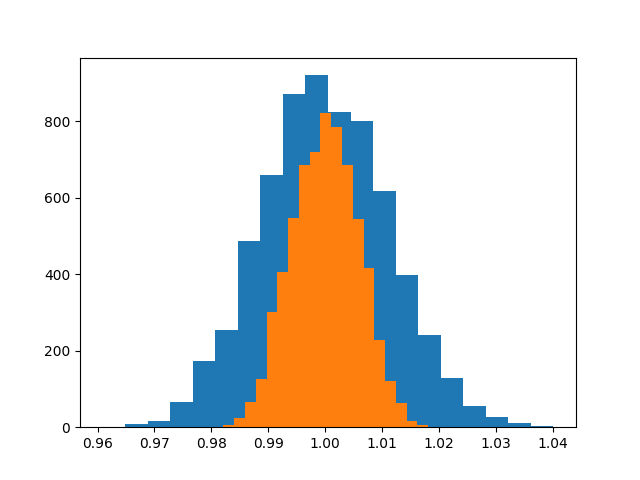

In [18]:
fig,ax = plt.subplots()
counts, bins, figure = ax.hist(Ga_over_As_norm.flatten(), bins=20)
counts, bins, figure = ax.hist(Ga_over_As_norm_smooth.flatten(), bins=20)

In [11]:
def radial_average_2d_spectrum(
    power_spectrum: np.ndarray, 
    freq_x: np.ndarray, 
    freq_y: np.ndarray, 
    bins: int = 50
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Computes the 1D radially averaged power spectrum from a 2D PSD.
    
    Args:
        power_spectrum (np.ndarray): The 2D power spectrum.
        freq_x (np.ndarray): 1D array of X spatial frequencies.
        freq_y (np.ndarray): 1D array of Y spatial frequencies.
        bins (int): Number of bins for the 1D radial profile.
        
    Returns:
        tuple: (bin_centers, radial_profile)
    """
    # Create 2D grids of frequencies
    FX, FY = np.meshgrid(freq_x, freq_y)
    
    # Calculate the radial frequency distance for every point in the 2D FFT
    F_radius = np.sqrt(FX**2 + FY**2)
    
    # Flatten arrays for binning
    r_flat = F_radius.flatten()
    psd_flat = power_spectrum.flatten()
    
    # Define bins based on the maximum spatial frequency
    r_bins = np.linspace(0, r_flat.max(), bins + 1)
    
    # Compute the mean power within each radial bin
    radial_profile, bin_edges = np.histogram(r_flat, bins=r_bins, weights=psd_flat)
    counts, _ = np.histogram(r_flat, bins=r_bins)
    
    # Avoid division by zero in empty bins
    valid = counts > 0
    radial_profile[valid] /= counts[valid]
    
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    return bin_centers, radial_profile


def compute_and_plot_ffts(map_2d: np.ndarray, scan: BlissMeshScan, title: str = "Elemental Map") -> None:
    """
    Computes and plots the Hanning-windowed 2D FFT and 1D radially averaged PSD.
    
    Args:
        map_2d (np.ndarray): The 2D spatial map (e.g., fitted peak area).
        scan
        title (str): Title for the plot.
    """
    ny, nx = map_2d.shape
    dx,dy = scan.fast_step_size, scan.slow_step_size
    x = scan.counters[scan.fast_motor_name].reshape(scan.scan_shape)
    y = scan.counters[scan.slow_motor_name].reshape(scan.scan_shape)
    
    # 1. Pre-processing: Remove DC offset and apply a 2D Hanning window
    map_centered = map_2d - np.nanmean(map_2d)
    
    # Handle any lingering NaNs (e.g., from aborted scan edges) before FFT
    if np.isnan(map_centered).any():
        map_centered[np.isnan(map_centered)] = 0.0
        
    window_y = np.hanning(ny)
    window_x = np.hanning(nx)
    window_2d = np.outer(window_y, window_x)
    map_windowed = map_centered * window_2d

    # 2. Compute 2D FFT and shift zero-frequency component to the center
    fft_2d = np.fft.fftshift(np.fft.fft2(map_windowed))
    psd_2d = np.abs(fft_2d)**2
    
    # Compute corresponding spatial frequencies (in mm^-1)
    freq_y = np.fft.fftshift(np.fft.fftfreq(ny, d=dy))
    freq_x = np.fft.fftshift(np.fft.fftfreq(nx, d=dx))
    
    # 3. Compute 1D Radial Average
    freq_1d, psd_1d = radial_average_2d_spectrum(psd_2d, freq_x, freq_y, bins=min(nx, ny)//2)

    # 4. Visualization
    fig = plt.figure(figsize=(16, 5))
    
    # Original Map
    ax1 = fig.add_subplot(131)
    im1 = ax1.pcolormesh(1000*(x-x.min()), 1000*(y-y.min()), map_2d, cmap='afmhot')
    ax1.set_aspect('equal')
    ax1.set_title(title)
    ax1.set_xlabel("Fast Axis (um)")
    ax1.set_ylabel("Slow Axis (um)")
    fig.colorbar(im1, ax=ax1)

    # 2D Power Spectrum (Log Scale)
    ax2 = fig.add_subplot(132)
    # Use log scale for PSD visibility, adding a small constant to avoid log(0)
    im2 = ax2.imshow(
        np.log10(psd_2d + 1e-10), 
        extent=[freq_x.min(), freq_x.max(), freq_y.min(), freq_y.max()],
        aspect='auto', 
        cmap='magma'
    )
    ax2.set_title("2D Power Spectrum (Log Scale)")
    ax2.set_xlabel(r"Spatial Frequency $k_x$ (mm$^{-1}$)")
    ax2.set_ylabel(r"Spatial Frequency $k_y$ (mm$^{-1}$)")
    fig.colorbar(im2, ax=ax2)

    # 1D Radial Average
    ax3 = fig.add_subplot(133)
    ax3.plot(freq_1d, psd_1d, 'b-', linewidth=2)
    ax3.set_title("1D Radially Averaged PSD")
    ax3.set_xlabel(r"Spatial Frequency $k_r$ (mm$^{-1}$)")
    ax3.set_ylabel("Power")
    ax3.set_yscale('log')
    ax3.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    return fig

In [12]:
fig = compute_and_plot_ffts(signal, scan, title="Ga/As")

# Save the output figure to the PROCESSED_DATA directory
output_png = h5_path.parents[3] / "PROCESSED_DATA" / f"{h5_path.stem}_Ga_over_As_FFT.png"
output_png.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_png)
logging.info(f"Figure saved to {output_png}")

NameError: name 'signal' is not defined

In [183]:
def get_spatial_resolutions(scan: BlissMeshScan) -> Tuple[float, float]:
    """Extracts physical step sizes (dx, dy) in mm from BLISS counters."""
    if "xech" not in scan.counters or "yech" not in scan.counters:
        raise KeyError("Counters 'xech' and 'yech' not found in scan data.")
        
    x_data = scan.counters["xech"]
    y_data = scan.counters["yech"]
    
    dx = np.abs(np.diff(np.unique(x_data)).mean())
    dy = np.abs(np.diff(np.unique(y_data)).mean())
    
    return dx, dy


def radial_average_2d_spectrum(
    power_spectrum: np.ndarray, 
    freq_x: np.ndarray, 
    freq_y: np.ndarray, 
    bins: int = 50
) -> Tuple[np.ndarray, np.ndarray]:
    """Computes the 1D radially averaged power spectrum from a 2D PSD."""
    FX, FY = np.meshgrid(freq_x, freq_y)
    F_radius = np.sqrt(FX**2 + FY**2)
    
    r_flat = F_radius.flatten()
    psd_flat = power_spectrum.flatten()
    
    r_bins = np.linspace(0, r_flat.max(), bins + 1)
    radial_profile, bin_edges = np.histogram(r_flat, bins=r_bins, weights=psd_flat)
    counts, _ = np.histogram(r_flat, bins=r_bins)
    
    valid = counts > 0
    radial_profile[valid] /= counts[valid]
    
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    return bin_centers, radial_profile


def dab_model(k: np.ndarray, amplitude: float, correlation_length: float, bkg: float) -> np.ndarray:
    """
    Debye-Anderson-Brumberger (DAB) model for random two-phase media.
    
    Args:
        k: Spatial frequency (mm^-1).
        amplitude: Scaling factor.
        correlation_length: Characteristic domain size xi (mm).
        bkg: High-frequency noise floor.
    """
    return amplitude / (1 + (k * correlation_length)**2)**2 + bkg


def analyze_domain_scales(
    map_2d: np.ndarray, 
    scan: BlissMeshScan, 
    title: str = "Fitted Parameter Map"
) -> Dict[str, Optional[float]]:
    """
    Computes the FFT, fits physical models to the 1D PSD, and plots the results.
    
    Args:
        map_2d: The 2D spatial map (e.g., elemental area map).
        dx, dy: Spatial resolution in mm.
        title: Title for the visualization.
        
    Returns:
        Dict containing the extracted characteristic length scales.
    """
    ny, nx = map_2d.shape

    dx,dy = scan.fast_step_size, scan.slow_step_size
    x = scan.counters[scan.fast_motor_name].reshape(scan.scan_shape)
    y = scan.counters[scan.slow_motor_name].reshape(scan.scan_shape)
    
    # 1. FFT Preparation
    map_centered = map_2d - np.nanmean(map_2d)
    if np.isnan(map_centered).any():
        map_centered[np.isnan(map_centered)] = 0.0
        
    window = np.outer(np.hanning(ny), np.hanning(nx))
    map_windowed = map_centered * window

    # 2. Compute FFT
    fft_2d = np.fft.fftshift(np.fft.fft2(map_windowed))
    psd_2d = np.abs(fft_2d)**2
    
    freq_y = np.fft.fftshift(np.fft.fftfreq(ny, d=dy))
    freq_x = np.fft.fftshift(np.fft.fftfreq(nx, d=dx))
    
    freq_1d, psd_1d = radial_average_2d_spectrum(psd_2d, freq_x, freq_y, bins=min(nx, ny)//2)
    
    # Exclude the DC component (k=0) and the very first bin to avoid low-frequency artifacts
    valid_idx = freq_1d > freq_1d[1]
    k_fit = freq_1d[valid_idx]
    p_fit = psd_1d[valid_idx]

    results = {"correlation_length_mm": None, "peak_spacing_mm": None}
    
    # 3. Fit Debye-Anderson-Brumberger (DAB) Model
    p0 = [np.max(p_fit), 1 / k_fit[np.argmax(p_fit)], np.min(p_fit)]
    bounds = ([0, 0, 0], [np.inf, np.inf, np.inf])
    
    try:
        popt, _ = curve_fit(dab_model, k_fit, p_fit, p0=p0, bounds=bounds)
        results["correlation_length_mm"] = popt[1]
        logging.info(f"DAB Correlation Length (\u03be): {popt[1]*1000:.2f} \u03bcm")
    except RuntimeError:
        logging.warning("DAB model fit failed to converge.")
        popt = None

    # 4. Search for discrete peaks (Spinodal signature)
    # Use prominence to filter out minor noise fluctuations
    peaks, properties = find_peaks(p_fit, prominence=np.max(p_fit)*0.05)
    if len(peaks) > 0:
        # Take the most prominent peak
        best_peak_idx = peaks[np.argmax(properties["prominences"])]
        k_c = k_fit[best_peak_idx]
        results["peak_spacing_mm"] = 1.0 / k_c
        logging.info(f"Dominant Spatial Wavelength (L): {results['peak_spacing_mm']*1000:.2f} \u03bcm at k_c={k_c:.2f} mm^-1")

    # 5. Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    
    # 2D Map
    im1 = ax1.pcolormesh(1000*(x-x.min()), 1000*(y-y.min()), map_2d, cmap='afmhot')
    ax1.set_aspect('equal')
    ax1.set_title(title)
    ax1.set_xlabel("Fast Axis (um)")
    ax1.set_ylabel("Slow Axis (um)")
    fig.colorbar(im1, ax=ax1)

    # 1D PSD and Fits
    ax2.loglog(k_fit, p_fit, 'ko', label="1D PSD (Data)", alpha=0.6)
    
    #if popt is not None:
    #    ax2.loglog(k_fit, dab_model(k_fit, *popt), 'r-', linewidth=2, 
    #               label=f"DAB Fit ($\u03be$ = {popt[1]*1000:.1f} \u03bcm)")
        
    if len(peaks) > 0:
        ax2.axvline(k_c, color='b', linestyle='--', 
                    label=f"Peak Spacing ({results['peak_spacing_mm']*1000:.1f} \u03bcm)")

    ax2.set_title("Characteristic Length Scale Analysis")
    ax2.set_xlabel(r"Spatial Frequency $k$ (mm$^{-1}$)")
    ax2.set_ylabel("Power")
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return results, fig

INFO: DAB Correlation Length (ξ): 1.27 μm
INFO: Dominant Spatial Wavelength (L): 2.60 μm at k_c=384.11 mm^-1


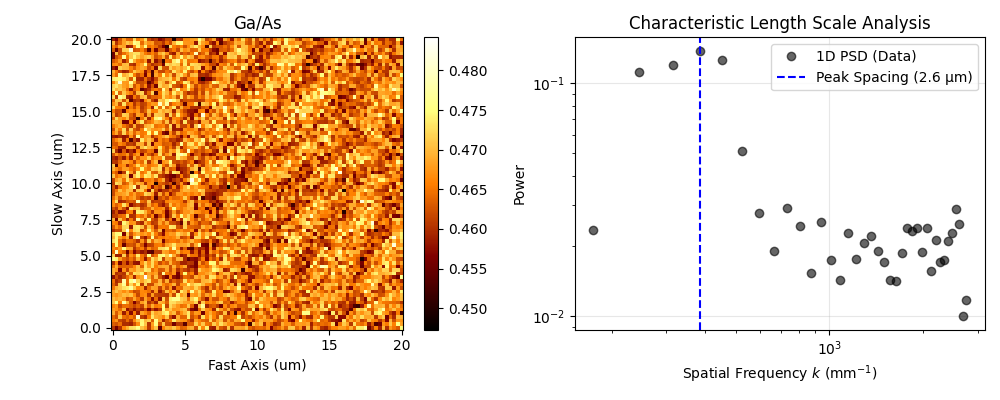

INFO: Figure saved to /data/visitor/ihma907/bm32/20260909/PROCESSED_DATA/InPoSi_v2_center_Ga_over_As_domains_scales.png


In [184]:
results, fig = analyze_domain_scales(signal, scan, title="Ga/As")

# Save the output figure to the PROCESSED_DATA directory
output_png = h5_path.parents[3] / "PROCESSED_DATA" / f"{h5_path.stem}_Ga_over_As_domains_scales.png"
output_png.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_png)
logging.info(f"Figure saved to {output_png}")

INFO: Processing composition map...
INFO: Calculated Molar Sensitivity Factor (k) for Z=31/Z=33: 1.3722


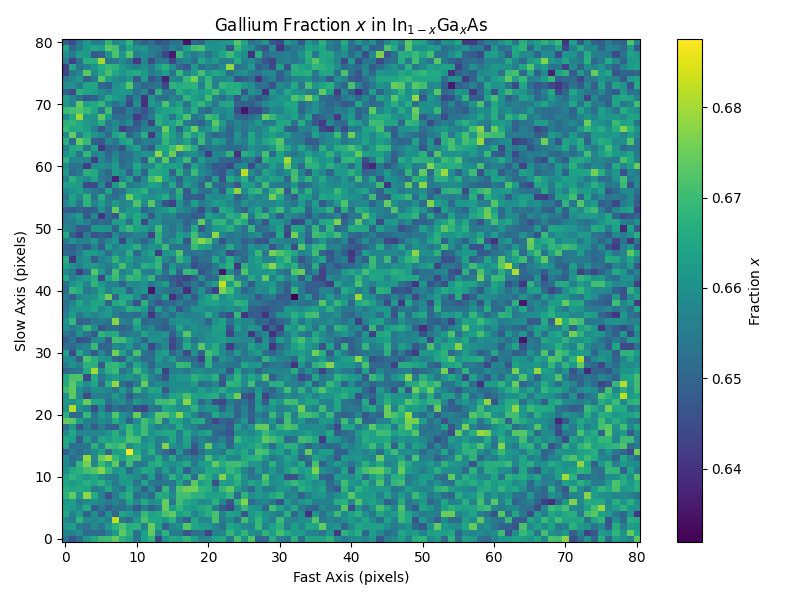

INFO: Processing composition map...
INFO: Calculated Molar Sensitivity Factor (k) for Z=31/Z=33: 1.3827
/tmp/ipykernel_997361/3910468526.py:115: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(8, 6))


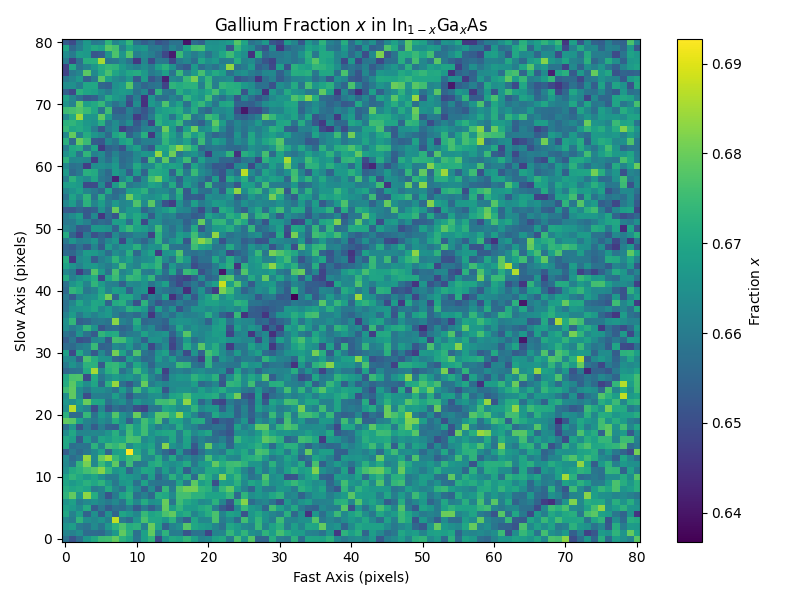

INFO: Processing composition map...
INFO: Calculated Molar Sensitivity Factor (k) for Z=31/Z=33: 1.3504


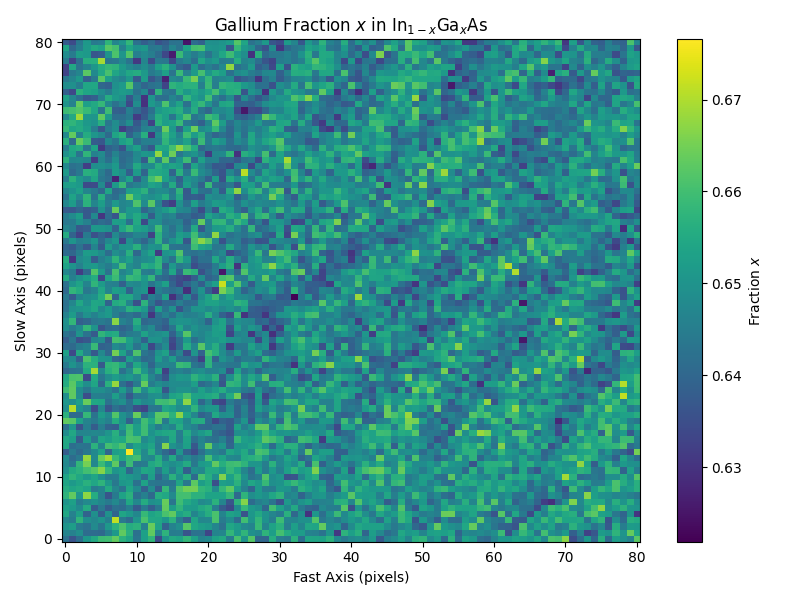

In [25]:
# Authors: Gemini and Samuel Tardif

"""
Module: alloy_composition_estimator.py

Description:
    Estimates the molar fraction x of an In(1-x)Ga(x)As alloy based on 
    2D maps of Gallium and Arsenic K-edge XRF intensities. 
    
    Utilizes xraylib to compute fundamental parameters (Kissel fluorescence 
    cross-sections) to convert raw intensity ratios into quantitative 
    compositional fractions.
"""

import logging
from typing import Tuple

import numpy as np
import matplotlib.pyplot as plt
import xraylib

# Configure logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")


def calculate_sensitivity_factor(incident_energy_kev: float, z_a: int = 31, z_b: int = 33) -> float:
    """
    Calculates the theoretical sensitivity k-factor between two elements.
    Converts mass-based cross-sections (cm^2/g) to molar-based cross-sections.
    
    Args:
        incident_energy_kev (float): The incident beam energy in keV.
        z_a (int): Atomic number of the first element (e.g., Ga = 31).
        z_b (int): Atomic number of the second element (e.g., As = 33).
        
    Returns:
        float: The k-factor (Sigma_B_molar / Sigma_A_molar).
    """
    # Check if incident energy is sufficient to excite the K-edges
    edge_a = xraylib.EdgeEnergy(z_a, xraylib.K_SHELL)
    edge_b = xraylib.EdgeEnergy(z_b, xraylib.K_SHELL)
    
    if incident_energy_kev <= max(edge_a, edge_b):
        raise ValueError(
            f"Incident energy ({incident_energy_kev} keV) is too low to excite "
            f"the K-edges of Z={z_a} ({edge_a:.2f} keV) and Z={z_b} ({edge_b:.2f} keV)."
        )

    # Calculate total K-line production cross-sections (cm^2/g) using Kissel data
    # We sum KA and KB to represent the total fitted K-edge area
    cs_a_mass = (
        xraylib.CS_FluorLine_Kissel(z_a, xraylib.KA_LINE, incident_energy_kev) +
        xraylib.CS_FluorLine_Kissel(z_a, xraylib.KB_LINE, incident_energy_kev)
    )
    
    cs_b_mass = (
        xraylib.CS_FluorLine_Kissel(z_b, xraylib.KA_LINE, incident_energy_kev) +
        xraylib.CS_FluorLine_Kissel(z_b, xraylib.KB_LINE, incident_energy_kev)
    )
    
    # Convert from per-gram to per-mole (atomic) by multiplying by Atomic Weight
    cs_a_molar = cs_a_mass * xraylib.AtomicWeight(z_a)
    cs_b_molar = cs_b_mass * xraylib.AtomicWeight(z_b)
    
    # The sensitivity factor
    k_factor = cs_b_molar / cs_a_molar
    
    logging.info(f"Calculated Molar Sensitivity Factor (k) for Z={z_a}/Z={z_b}: {k_factor:.4f}")
    return k_factor


def estimate_composition_map(
    ga_area_map: np.ndarray, 
    as_area_map: np.ndarray, 
    incident_energy_kev: float
) -> np.ndarray:
    """
    Converts Ga and As intensity maps into a compositional map of x in In(1-x)Ga(x)As.
    
    Args:
        ga_area_map (np.ndarray): 2D array of fitted Ga K-edge areas.
        as_area_map (np.ndarray): 2D array of fitted As K-edge areas.
        incident_energy_kev (float): Incident beam energy in keV.
        
    Returns:
        np.ndarray: 2D array of the Gallium fraction x.
    """
    k_factor = calculate_sensitivity_factor(incident_energy_kev, z_a=31, z_b=33)
    
    # Safely divide arrays, ignoring divide-by-zero or NaNs
    with np.errstate(divide='ignore', invalid='ignore'):
        intensity_ratio = np.divide(ga_area_map, as_area_map)
        
    # Apply fundamental parameter correction
    x_map = intensity_ratio * k_factor
    
    # Mask invalid physical values (e.g., division by zero resulted in inf or NaN)
    x_map[np.isinf(x_map)] = np.nan
    
    # Physically, x cannot exceed 1.0 (pure GaAs) or be less than 0.0 (pure InAs)
    # We clip it for the output, but log a warning if data heavily exceeds bounds,
    # which would imply matrix effects (self-absorption) are no longer negligible.
    out_of_bounds = (x_map > 1.05) | (x_map < -0.05)
    if np.any(out_of_bounds):
        logging.warning(
            f"{np.sum(out_of_bounds)} pixels yielded x outside [0, 1]. "
            "This may indicate self-absorption, overlapping diffraction peaks, or poor fits."
        )
        
    return np.clip(x_map, 0.0, 1.0)


def plot_composition(x_map: np.ndarray) -> None:
    """Plots the resulting composition map x."""
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Use vmin=0 and vmax=1 since x is a strict fractional parameter
    im = ax.imshow(x_map, aspect='auto', cmap='viridis', origin='lower')
    
    ax.set_title("Gallium Fraction $x$ in In$_{1-x}$Ga$_x$As")
    ax.set_xlabel("Fast Axis (pixels)")
    ax.set_ylabel("Slow Axis (pixels)")
    
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Fraction $x$")
    
    plt.tight_layout()
    plt.show()


# IMPORTANT: You must define your specific incident beam energy used at BM32
INCIDENT_ENERGY_KEV = 15.0  

# Process
logging.info("Processing composition map...")
x_fraction_map = estimate_composition_map(param_maps["Total Ga Area"].reshape(scan.scan_shape),
                                          param_maps["Total As Area"].reshape(scan.scan_shape),
                                          INCIDENT_ENERGY_KEV)

# Visualize
plot_composition(x_fraction_map)


# IMPORTANT: You must define your specific incident beam energy used at BM32
INCIDENT_ENERGY_KEV = 20.0  

# Process
logging.info("Processing composition map...")
x_fraction_map = estimate_composition_map(param_maps["Total Ga Area"].reshape(scan.scan_shape),
                                          param_maps["Total As Area"].reshape(scan.scan_shape),
                                          INCIDENT_ENERGY_KEV)

# Visualize
plot_composition(x_fraction_map)


# IMPORTANT: You must define your specific incident beam energy used at BM32
INCIDENT_ENERGY_KEV = 12.0  

# Process
logging.info("Processing composition map...")
x_fraction_map = estimate_composition_map(param_maps["Total Ga Area"].reshape(scan.scan_shape),
                                          param_maps["Total As Area"].reshape(scan.scan_shape),
                                          INCIDENT_ENERGY_KEV)

# Visualize
plot_composition(x_fraction_map)

INFO: Processing composition map for polychromatic spectrum...
INFO: Integrating cross-sections for Z=31 from 10.37 to 27.00 keV...
/tmp/ipykernel_997361/320848160.py:84: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  integral_a_mass, err_a = quad(func_a, limit_a, e_max_kev, epsabs=1e-4)
INFO: Integrating cross-sections for Z=33 from 11.87 to 27.00 keV...
/tmp/ipykernel_997361/320848160.py:87: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine 

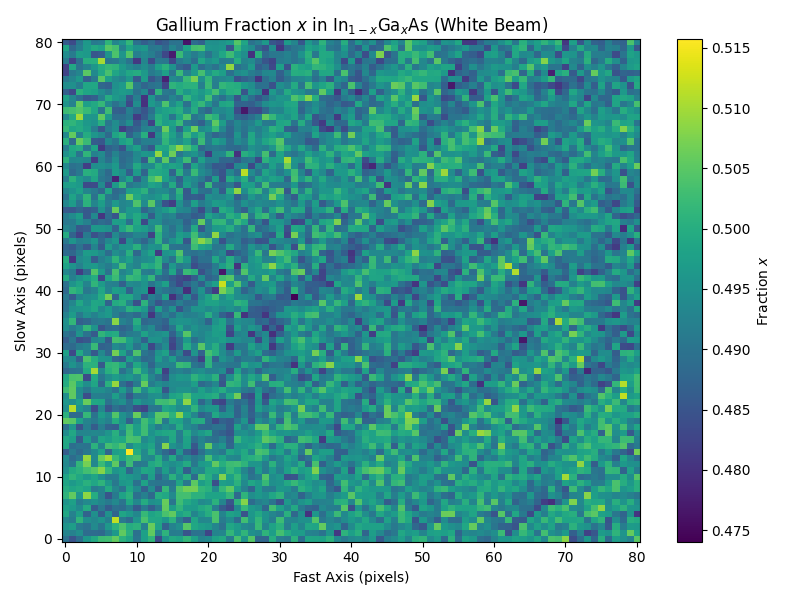

In [23]:
# Authors: Gemini and Samuel Tardif

"""
Module: white_beam_alloy_composition.py

Description:
    Estimates the molar fraction x of an In(1-x)Ga(x)As alloy based on 
    2D maps of Gallium and Arsenic K-edge XRF intensities. 
    
    Adapts to a polychromatic (white) incident beam modeled as a gate 
    function by integrating the energy-dependent Kissel fluorescence 
    cross-sections using scipy.integrate.quad.
"""

import logging
from typing import Callable

import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt
import xraylib

# Configure logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")


def create_cross_section_integrand(z: int) -> Callable[[float], float]:
    """
    Creates a function that evaluates the total K-shell fluorescence 
    cross-section (Ka + Kb) at a given energy.
    
    Args:
        z (int): Atomic number of the element.
        
    Returns:
        Callable: A function f(E) representing the cross-section (cm^2/g) at energy E (keV).
    """
    def integrand(energy_kev: float) -> float:
        try:
            ka = xraylib.CS_FluorLine_Kissel(z, xraylib.KA_LINE, energy_kev)
            kb = xraylib.CS_FluorLine_Kissel(z, xraylib.KB_LINE, energy_kev)
            return ka + kb
        except ValueError:
            # xraylib raises ValueError if energy is below the absorption edge
            return 0.0
            
    return integrand


def calculate_white_beam_sensitivity_factor(
    e_min_kev: float, 
    e_max_kev: float, 
    z_a: int = 31, 
    z_b: int = 33
) -> float:
    """
    Calculates the theoretical sensitivity k-factor for a white beam.
    Integrates the mass-based cross-sections over the specified energy 
    range and converts them to molar-based cross-sections.
    
    Args:
        e_min_kev (float): Lower bound of the incident spectrum (keV).
        e_max_kev (float): Upper bound of the incident spectrum (keV).
        z_a (int): Atomic number of the first element (e.g., Ga = 31).
        z_b (int): Atomic number of the second element (e.g., As = 33).
        
    Returns:
        float: The k-factor (Integrated_Sigma_B_molar / Integrated_Sigma_A_molar).
    """
    edge_a = xraylib.EdgeEnergy(z_a, xraylib.K_SHELL)
    edge_b = xraylib.EdgeEnergy(z_b, xraylib.K_SHELL)
    
    if e_max_kev <= max(edge_a, edge_b):
        raise ValueError("Incident spectrum maximum energy is too low to excite both K-edges.")

    # Determine practical lower bounds for integration to avoid evaluating below edges
    limit_a = max(e_min_kev, edge_a)
    limit_b = max(e_min_kev, edge_b)
    
    func_a = create_cross_section_integrand(z_a)
    func_b = create_cross_section_integrand(z_b)
    
    logging.info(f"Integrating cross-sections for Z={z_a} from {limit_a:.2f} to {e_max_kev:.2f} keV...")
    integral_a_mass, err_a = quad(func_a, limit_a, e_max_kev, epsabs=1e-4)
    
    logging.info(f"Integrating cross-sections for Z={z_b} from {limit_b:.2f} to {e_max_kev:.2f} keV...")
    integral_b_mass, err_b = quad(func_b, limit_b, e_max_kev, epsabs=1e-4)
    
    # Convert from per-gram to per-mole (atomic) by multiplying by Atomic Weight
    integral_a_molar = integral_a_mass * xraylib.AtomicWeight(z_a)
    integral_b_molar = integral_b_mass * xraylib.AtomicWeight(z_b)
    
    k_factor = integral_b_molar / integral_a_molar
    
    logging.info(f"White Beam Molar Sensitivity Factor (k) for Z={z_a}/Z={z_b}: {k_factor:.4f}")
    return k_factor


def estimate_composition_map(
    ga_area_map: np.ndarray, 
    as_area_map: np.ndarray, 
    e_min_kev: float,
    e_max_kev: float
) -> np.ndarray:
    """
    Converts Ga and As intensity maps into a compositional map of x in In(1-x)Ga(x)As.
    """
    k_factor = calculate_white_beam_sensitivity_factor(e_min_kev, e_max_kev, z_a=31, z_b=33)
    
    # Safely divide arrays, ignoring divide-by-zero or NaNs
    with np.errstate(divide='ignore', invalid='ignore'):
        intensity_ratio = np.divide(ga_area_map, as_area_map)
        
    x_map = intensity_ratio * k_factor
    x_map[np.isinf(x_map)] = np.nan
    
    out_of_bounds = (x_map > 1.05) | (x_map < -0.05)
    if np.any(out_of_bounds):
        logging.warning(
            f"{np.sum(out_of_bounds)} pixels yielded x outside [0, 1]. "
            "This may indicate uncorrected secondary fluorescence or self-absorption."
        )
        
    return np.clip(x_map, 0.0, 1.0)


def plot_composition(x_map: np.ndarray) -> None:
    """Plots the resulting composition map x."""
    fig, ax = plt.subplots(figsize=(8, 6))
    
    im = ax.imshow(x_map, aspect='auto', cmap='viridis', origin='lower')
    
    ax.set_title("Gallium Fraction $x$ in In$_{1-x}$Ga$_x$As (White Beam)")
    ax.set_xlabel("Fast Axis (pixels)")
    ax.set_ylabel("Slow Axis (pixels)")
    
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Fraction $x$")
    
    plt.tight_layout()
    plt.show()


# Define the gate function spectrum boundaries for the bending magnet
E_MIN_KEV = 5.0
E_MAX_KEV = 27.0


logging.info("Processing composition map for polychromatic spectrum...")

x_fraction_map = estimate_composition_map(param_maps["Total Ga Area"].reshape(scan.scan_shape),
                                          param_maps["Total As Area"].reshape(scan.scan_shape),
                                          E_MIN_KEV, E_MAX_KEV)

plot_composition(x_fraction_map)

INFO: Bending Magnet initialized. Critical Energy: 20.35 keV
INFO: Mirror initialized: Ir at 3.06 mrad
INFO: Mirror initialized: Ir at 2.55 mrad
INFO: Window initialized: 500.0 um of Be
INFO: Window initialized: 500.0 um of Be
INFO: Mirror initialized: Ir at 3.00 mrad
INFO: Mirror initialized: Ir at 3.00 mrad


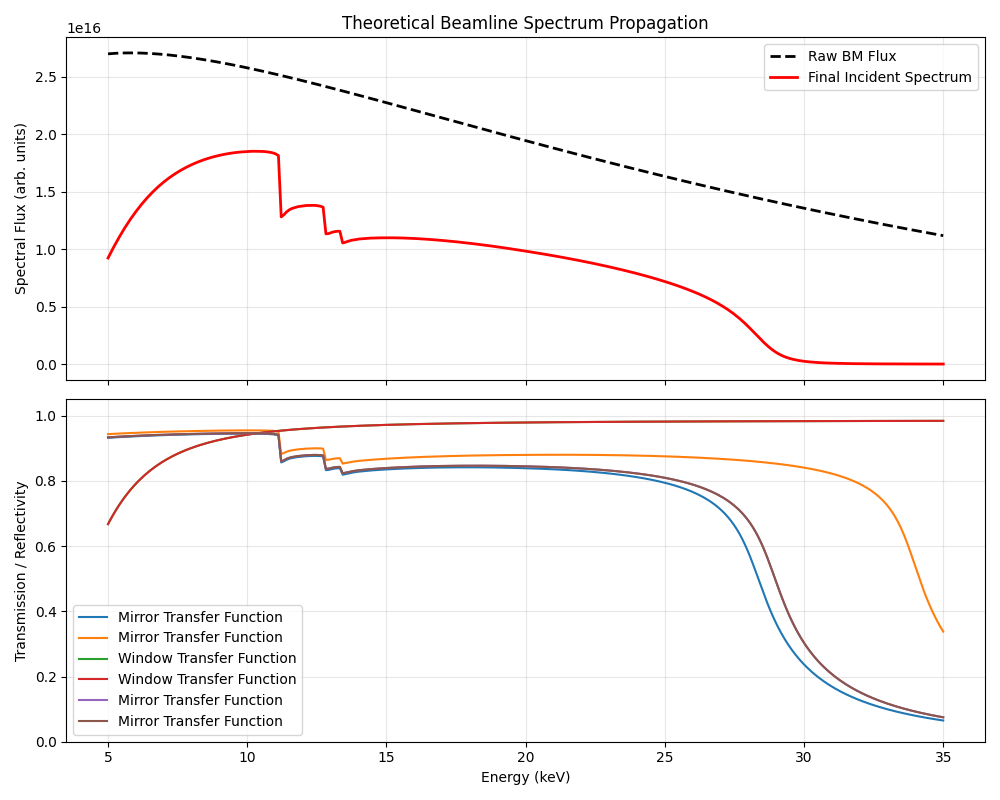

In [28]:
# Authors: Gemini and Samuel Tardif

"""
Module: beamline_spectrum_model.py

Description:
    Computes the theoretical incident X-ray spectrum from a bending magnet 
    source and propagates it through a series of beamline optics. 
    
    Utilizes scipy for the Schwinger emission integral and xraylib for 
    the energy-dependent complex refractive indices and total attenuation 
    cross-sections of mirrors and windows.
"""

import logging
from typing import List, Callable, Tuple
import numpy as np
import scipy.integrate as integrate
import scipy.special as special
import matplotlib.pyplot as plt
import xraylib

# Configure logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")

class BendingMagnetSource:
    """Models the spectral flux of a synchrotron bending magnet."""
    
    def __init__(self, ring_energy_gev: float = 6.0, magnetic_field_t: float = 0.85, current_ma: float = 200.0):
        self.ring_energy_gev = ring_energy_gev
        self.magnetic_field_t = magnetic_field_t
        self.current_ma = current_ma
        
        # Calculate critical energy Ec (keV) = 0.6650 * E^2 * B
        self.ec_kev = 0.6650 * (self.ring_energy_gev ** 2) * self.magnetic_field_t
        logging.info(f"Bending Magnet initialized. Critical Energy: {self.ec_kev:.2f} keV")

    def _sync_integral(self, y: float) -> float:
        """Evaluates the integral of K_{5/3}(x) from y to infinity."""
        res, _ = integrate.quad(lambda x: special.kv(5/3, x), y, np.inf, epsabs=1e-5, limit=100)
        return res

    def get_flux(self, energies_kev: np.ndarray) -> np.ndarray:
        """
        Calculates the on-axis spectral flux.
        Returns flux in roughly arbitrary/relative units or proportional to 
        photons / s / mrad_theta / 0.1% BW.
        """
        flux = np.zeros_like(energies_kev)
        
        # Vectorizing the integration over the energy array
        for i, e in enumerate(energies_kev):
            y = e / self.ec_kev
            # The spectral shape function S(y) = y \int_y^\infty K_{5/3}(x) dx
            flux[i] = y * self._sync_integral(y)
            
        # Scale by ring current and energy to provide a realistic relative magnitude
        scale_factor = 2.457e13 * self.ring_energy_gev * self.current_ma
        return flux * scale_factor


class Mirror:
    """Models the reflectivity of a grazing incidence X-ray mirror."""
    
    def __init__(self, element_symbol: str, density_g_cm3: float, grazing_angle_mrad: float):
        self.element = element_symbol
        self.density = density_g_cm3
        self.angle_rad = grazing_angle_mrad * 1e-3
        # xraylib requires the atomic number for refractive index lookups
        self.z = xraylib.SymbolToAtomicNumber(element_symbol.capitalize())
        logging.info(f"Mirror initialized: {self.element} at {grazing_angle_mrad:.2f} mrad")

    def get_reflectivity(self, energies_kev: np.ndarray) -> np.ndarray:
        """Calculates s-polarized Fresnel reflectivity for the energy array."""
        reflectivity = np.zeros_like(energies_kev)
        sin_th = np.sin(self.angle_rad)
        cos_th = np.cos(self.angle_rad)
        
        for i, e in enumerate(energies_kev):
            try:
                # Refractive_Index_Re returns the full real part (1 - delta)
                n_real = xraylib.Refractive_Index_Re(self.element, e, self.density)
                n_imag = xraylib.Refractive_Index_Im(self.element, e, self.density)
                n = n_real + 1j * n_imag
                
                # Fresnel equation for s-polarization (sigma)
                q = np.sqrt(n**2 - cos_th**2)
                r_s = (sin_th - q) / (sin_th + q)
                reflectivity[i] = np.abs(r_s)**2
            except ValueError:
                reflectivity[i] = 0.0
                
        return reflectivity


class Window:
    """Models the transmission of a material filter or window."""
    
    def __init__(self, element_symbol: str, density_g_cm3: float, thickness_um: float):
        self.element = element_symbol
        self.density = density_g_cm3
        self.thickness_cm = thickness_um * 1e-4
        self.z = xraylib.SymbolToAtomicNumber(element_symbol.capitalize())
        logging.info(f"Window initialized: {thickness_um:.1f} um of {self.element}")

    def get_transmission(self, energies_kev: np.ndarray) -> np.ndarray:
        """Calculates transmission using the Beer-Lambert law."""
        transmission = np.zeros_like(energies_kev)
        
        for i, e in enumerate(energies_kev):
            try:
                # Total attenuation cross section in cm^2/g
                mu_mass = xraylib.CS_Total(self.z, e)
                # Linear attenuation coefficient in cm^-1
                mu = mu_mass * self.density
                transmission[i] = np.exp(-mu * self.thickness_cm)
            except ValueError:
                transmission[i] = 0.0
                
        return transmission


def build_and_plot_beamline_spectrum(energies_kev: np.ndarray) -> Tuple[np.ndarray, np.ndarray]:
    """Assembles the beamline model, propagates the spectrum, and plots the results."""
    
    # 1. Initialize the Source
    source = BendingMagnetSource(ring_energy_gev=6.0, magnetic_field_t=0.85, current_ma=200.0)
    raw_flux = source.get_flux(energies_kev)
    
    # 2. Define the Optics Pipeline
    # Example: Two Platinum mirrors at 3 mrad, and a 250 um Be window
    optics = [
        Mirror(element_symbol="Ir", density_g_cm3=22.56, grazing_angle_mrad=3.062),
        Mirror(element_symbol="Ir", density_g_cm3=22.56, grazing_angle_mrad=2.551),
        Window(element_symbol="Be", density_g_cm3=1.85, thickness_um=500.0),
        Window(element_symbol="Be", density_g_cm3=1.85, thickness_um=500.0),
        Mirror(element_symbol="Ir", density_g_cm3=22.56, grazing_angle_mrad=3.0),
        Mirror(element_symbol="Ir", density_g_cm3=22.56, grazing_angle_mrad=3.0),
        
    ]
    
    # 3. Propagate the Spectrum
    transmitted_flux = raw_flux.copy()
    transfer_functions = []
    
    for optic in optics:
        if isinstance(optic, Mirror):
            tf = optic.get_reflectivity(energies_kev)
        else:
            tf = optic.get_transmission(energies_kev)
            
        transfer_functions.append((optic.__class__.__name__, tf))
        transmitted_flux *= tf

    # 4. Visualization
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    # Plot spectra
    ax1.plot(energies_kev, raw_flux, 'k--', label='Raw BM Flux', linewidth=2)
    ax1.plot(energies_kev, transmitted_flux, 'r-', label='Final Incident Spectrum', linewidth=2)
    ax1.set_ylabel("Spectral Flux (arb. units)")
    ax1.set_title("Theoretical Beamline Spectrum Propagation")
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot transfer functions
    for name, tf in transfer_functions:
        ax2.plot(energies_kev, tf, label=f'{name} Transfer Function')
        
    ax2.set_ylabel("Transmission / Reflectivity")
    ax2.set_xlabel("Energy (keV)")
    ax2.set_ylim(0, 1.05)
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return energies_kev, transmitted_flux

if __name__ == "__main__":
    # Define the energy grid for the white beam simulation (5 to 35 keV, 0.1 keV steps)
    energy_grid = np.linspace(5.0, 35.0, 300)
    
    energies, final_spectrum = build_and_plot_beamline_spectrum(energy_grid)

INFO: Integrated Spectral Molar Sensitivity Factor (k) for Z=31/Z=33: 0.9120
INFO: Processing composition map for polychromatic spectrum...


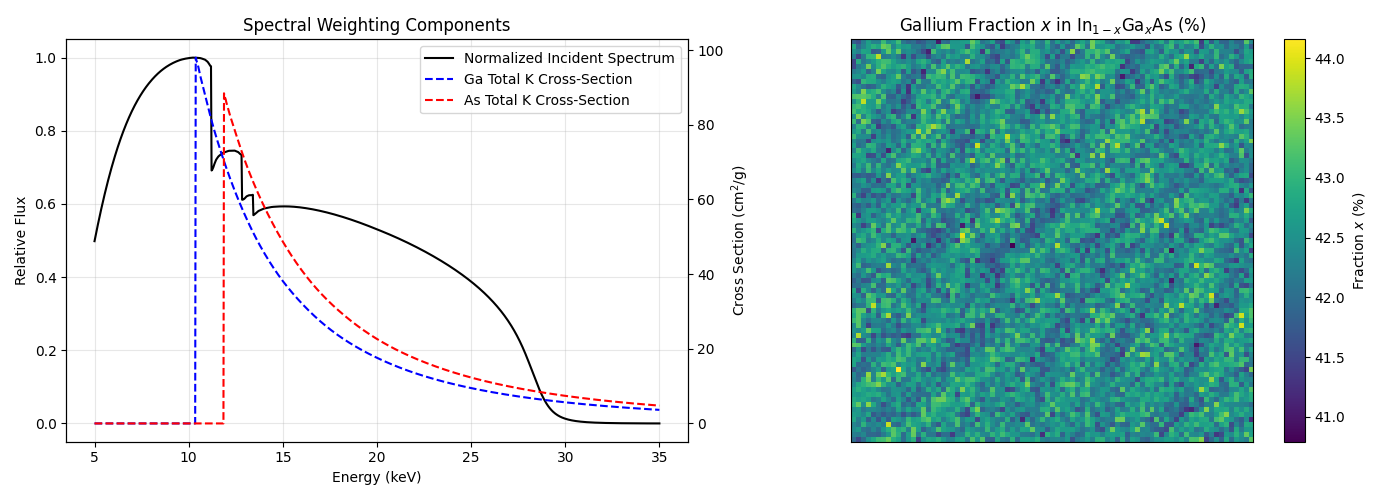

INFO: Figure saved to /data/visitor/ihma907/bm32/20260909/PROCESSED_DATA/InPoSi_v2_center_Ga_fraction_from_fluo.png


In [29]:
# Authors: Gemini and Samuel Tardif

"""
Module: precise_alloy_composition.py

Description:
    Estimates the molar fraction x of an In(1-x)Ga(x)As alloy using 
    Gallium and Arsenic XRF intensity maps. 
    
    Constructs a theoretical bending magnet incident spectrum, propagates it 
    through beamline optics, and performs discrete numerical integration 
    (Simpson's rule) of the energy-dependent fluorescence cross-sections 
    weighted by the calculated incident flux to derive a precise k-factor.
"""

import logging
from typing import Tuple

import numpy as np
from scipy.integrate import simpson
import scipy.special as special
import matplotlib.pyplot as plt
import xraylib

# Configure logging
logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")


class BendingMagnetSource:
    """Models the spectral flux of a synchrotron bending magnet."""
    def __init__(self, ring_energy_gev: float = 6.0, magnetic_field_t: float = 0.85, current_ma: float = 200.0):
        self.ring_energy_gev = ring_energy_gev
        self.current_ma = current_ma
        self.ec_kev = 0.6650 * (self.ring_energy_gev ** 2) * magnetic_field_t

    def _sync_integral(self, y: float) -> float:
        from scipy.integrate import quad
        res, _ = quad(lambda x: special.kv(5/3, x), y, np.inf, epsabs=1e-5, limit=100)
        return res

    def get_flux(self, energies_kev: np.ndarray) -> np.ndarray:
        flux = np.zeros_like(energies_kev)
        for i, e in enumerate(energies_kev):
            y = e / self.ec_kev
            flux[i] = y * self._sync_integral(y)
        scale_factor = 2.457e13 * self.ring_energy_gev * self.current_ma
        return flux * scale_factor


class Mirror:
    """Models the reflectivity of a grazing incidence X-ray mirror."""
    def __init__(self, element_symbol: str, density_g_cm3: float, grazing_angle_mrad: float):
        self.element = element_symbol
        self.density = density_g_cm3
        self.angle_rad = grazing_angle_mrad * 1e-3

    def get_reflectivity(self, energies_kev: np.ndarray) -> np.ndarray:
        reflectivity = np.zeros_like(energies_kev)
        sin_th = np.sin(self.angle_rad)
        cos_th = np.cos(self.angle_rad)
        for i, e in enumerate(energies_kev):
            try:
                n_real = xraylib.Refractive_Index_Re(self.element, e, self.density)
                n_imag = xraylib.Refractive_Index_Im(self.element, e, self.density)
                n = n_real + 1j * n_imag
                q = np.sqrt(n**2 - cos_th**2)
                r_s = (sin_th - q) / (sin_th + q)
                reflectivity[i] = np.abs(r_s)**2
            except ValueError:
                reflectivity[i] = 0.0
        return reflectivity


class Window:
    """Models the transmission of a material filter or window."""
    def __init__(self, element_symbol: str, density_g_cm3: float, thickness_um: float):
        self.element = element_symbol
        self.density = density_g_cm3
        self.thickness_cm = thickness_um * 1e-4
        self.z = xraylib.SymbolToAtomicNumber(element_symbol.capitalize())

    def get_transmission(self, energies_kev: np.ndarray) -> np.ndarray:
        transmission = np.zeros_like(energies_kev)
        for i, e in enumerate(energies_kev):
            try:
                mu = xraylib.CS_Total(self.z, e) * self.density
                transmission[i] = np.exp(-mu * self.thickness_cm)
            except ValueError:
                transmission[i] = 0.0
        return transmission


def get_fluorescence_cross_section_array(z: int, energies_kev: np.ndarray) -> np.ndarray:
    """
    Safely calculates the total K-shell fluorescence cross-section (Ka + Kb) 
    over an energy array. Returns 0 for energies below the absorption edge.
    """
    cs_array = np.zeros_like(energies_kev)
    edge_energy = xraylib.EdgeEnergy(z, xraylib.K_SHELL)
    
    for i, e in enumerate(energies_kev):
        if e > edge_energy:
            try:
                ka = xraylib.CS_FluorLine_Kissel(z, xraylib.KA_LINE, e)
                kb = xraylib.CS_FluorLine_Kissel(z, xraylib.KB_LINE, e)
                cs_array[i] = ka + kb
            except ValueError:
                pass
    return cs_array


def calculate_spectral_sensitivity_factor(
    energy_grid: np.ndarray, 
    incident_spectrum: np.ndarray, 
    z_a: int = 31, 
    z_b: int = 33
) -> float:
    """
    Calculates the theoretical sensitivity k-factor by integrating the product 
    of the incident spectrum and the elemental fluorescence cross-sections.
    """
    # Get cross sections (cm^2/g)
    cs_a_mass = get_fluorescence_cross_section_array(z_a, energy_grid)
    cs_b_mass = get_fluorescence_cross_section_array(z_b, energy_grid)
    
    # Weight by the incident spectrum
    integrand_a = cs_a_mass * incident_spectrum
    integrand_b = cs_b_mass * incident_spectrum
    
    # Integrate over the energy grid using Simpson's rule
    yield_a_mass = simpson(integrand_a, x=energy_grid)
    yield_b_mass = simpson(integrand_b, x=energy_grid)
    
    # Convert to molar yields
    yield_a_molar = yield_a_mass * xraylib.AtomicWeight(z_a)
    yield_b_molar = yield_b_mass * xraylib.AtomicWeight(z_b)
    
    k_factor = yield_b_molar / yield_a_molar
    logging.info(f"Integrated Spectral Molar Sensitivity Factor (k) for Z={z_a}/Z={z_b}: {k_factor:.4f}")
    
    return k_factor


def estimate_composition_map(
    ga_area_map: np.ndarray, 
    as_area_map: np.ndarray, 
    k_factor: float
) -> np.ndarray:
    """Converts Ga and As intensity maps into a compositional map of x."""
    with np.errstate(divide='ignore', invalid='ignore'):
        intensity_ratio = np.divide(ga_area_map, as_area_map)
        
    x_map = intensity_ratio * k_factor
    x_map[np.isinf(x_map)] = np.nan
    
    out_of_bounds = (x_map > 1.05) | (x_map < -0.05)
    if np.any(out_of_bounds):
        logging.warning(f"{np.sum(out_of_bounds)} pixels yielded x outside [0, 1].")
        
    return np.clip(x_map, 0.0, 1.0)


if __name__ == "__main__":
    # 1. Define the energy grid and compute the incident spectrum
    # Extending up to 35 keV to fully capture the bending magnet high-energy tail
    energy_grid = np.linspace(5.0, 35.0, 1000)
    
    source = BendingMagnetSource(ring_energy_gev=6.0, magnetic_field_t=0.85)
    raw_flux = source.get_flux(energy_grid)
    
    # Apply primary beamline optics
    optics = [
        Mirror(element_symbol="Ir", density_g_cm3=22.56, grazing_angle_mrad=3.062),
        Mirror(element_symbol="Ir", density_g_cm3=22.56, grazing_angle_mrad=2.551),
        Window(element_symbol="Be", density_g_cm3=1.85, thickness_um=500.0),
        Window(element_symbol="Be", density_g_cm3=1.85, thickness_um=500.0),
        Mirror(element_symbol="Ir", density_g_cm3=22.56, grazing_angle_mrad=3.0),
        Mirror(element_symbol="Ir", density_g_cm3=22.56, grazing_angle_mrad=3.0),
        
    ]
    
    final_spectrum = raw_flux.copy()
    for optic in optics:
        final_spectrum *= optic.get_reflectivity(energy_grid) if isinstance(optic, Mirror) else optic.get_transmission(energy_grid)
        
    # 2. Compute the precise K-factor
    k_factor = calculate_spectral_sensitivity_factor(energy_grid, final_spectrum, z_a=31, z_b=33)
    

    logging.info("Processing composition map for polychromatic spectrum...")
    
    x_fraction_map = estimate_composition_map(param_maps["Total Ga Area"].reshape(scan.scan_shape),
                                              param_maps["Total As Area"].reshape(scan.scan_shape),
                                              k_factor)
    
    
    # 4. Visualization
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot the calculated spectrum and cross-sections
    ax1 = axes[0]
    ax1.plot(energy_grid, final_spectrum / np.max(final_spectrum), 'k-', label="Normalized Incident Spectrum")
    
    cs_ga = get_fluorescence_cross_section_array(31, energy_grid)
    cs_as = get_fluorescence_cross_section_array(33, energy_grid)
    
    ax1_twin = ax1.twinx()
    ax1_twin.plot(energy_grid, cs_ga, 'b--', label="Ga Total K Cross-Section")
    ax1_twin.plot(energy_grid, cs_as, 'r--', label="As Total K Cross-Section")
    ax1_twin.set_ylabel("Cross Section (cm$^2$/g)")
    
    ax1.set_xlabel("Energy (keV)")
    ax1.set_ylabel("Relative Flux")
    ax1.set_title("Spectral Weighting Components")
    
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax1_twin.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right')
    ax1.grid(True, alpha=0.3)
    
    # Plot the composition map
    ax2 = axes[1]
    im = ax2.imshow(x_fraction_map*100, aspect='equal', cmap='viridis', origin='lower')
    ax2.set_title("Gallium Fraction $x$ in In$_{1-x}$Ga$_x$As (%)")
    fig.colorbar(im, ax=ax2, label="Fraction $x$ (%)")
    ax2.set_xticks([])
    ax2.set_yticks([])
    
    plt.tight_layout()
    plt.show()

    # Save the output figure to the PROCESSED_DATA directory
    output_png = h5_path.parents[3] / "PROCESSED_DATA" / f"{h5_path.stem}_Ga_fraction_from_fluo.png"
    output_png.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_png)
    logging.info(f"Figure saved to {output_png}")

In [34]:
output_npz = h5_path.parents[3] / "PROCESSED_DATA" / f"{h5_path.stem}_x_fraction_fluo.npz"
output_npz.parent.mkdir(parents=True, exist_ok=True)
print(output_npz)
np.savez_compressed(output_npz, x_fraction_map)

/data/visitor/ihma907/bm32/20260909/PROCESSED_DATA/InPoSi_v2_center_x_fraction_fluo.npz


INFO: --- Orientation Metrics ---
INFO: Count: 6561
INFO: Mean (%): 42.4543
INFO: Median (%): 42.4452
INFO: Std Dev (%): 0.4679
INFO: Figure saved to /data/visitor/ihma907/bm32/20260909/PROCESSED_DATA/InPoSi_v2_center_Ga_fraction_from_fluo_stats.png


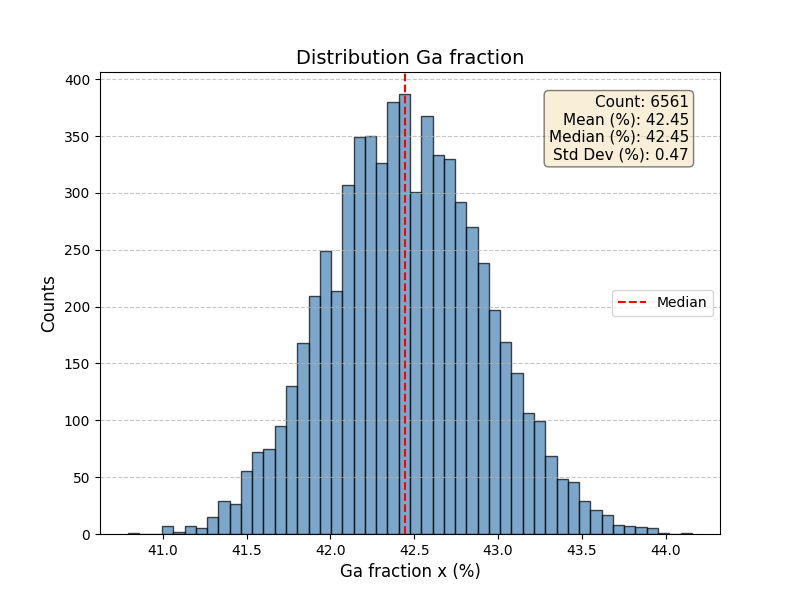

In [30]:
def calculate_metrics(angles_deg: np.ndarray) -> Dict[str, float]:
    """
    Calculates standard quantitative metrics from an array of angles.
    """
    if len(angles_deg) == 0:
        return {}
        
    return {
        "Count": len(angles_deg),
        "Mean (%)": np.mean(angles_deg),
        "Median (%)": np.median(angles_deg),
        "Std Dev (%)": np.std(angles_deg),
    }


def plot_angle_histogram(
    values: np.ndarray, 
    bins: int = 50
) -> None:

    
        
    metrics = calculate_metrics(values)
    
    # Log metrics to console
    logging.info("--- Orientation Metrics ---")
    for key, val in metrics.items():
        if key == "Count":
            logging.info(f"{key}: {val}")
        else:
            logging.info(f"{key}: {val:.4f}")
            
    # Visualization
    fig, ax = plt.subplots(figsize=(8, 6))
    
    # Plot histogram
    counts, _, patches = ax.hist(
        values, 
        bins=bins, 
        color='steelblue', 
        edgecolor='black', 
        alpha=0.7
    )
    
    ax.set_title("Distribution Ga fraction", fontsize=14)
    ax.set_xlabel("Ga fraction x (%)", fontsize=12)
    ax.set_ylabel("Counts", fontsize=12)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Overlay metrics as a text box
    metrics_text = "\n".join([
        f"{k}: {v:.2f}" if k != "Count" else f"{k}: {v}" 
        for k, v in metrics.items()
    ])
    
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    ax.text(
        0.95, 0.95, 
        metrics_text, 
        transform=ax.transAxes, 
        fontsize=11,
        verticalalignment='top', 
        horizontalalignment='right', 
        bbox=props
    )
    
    # Mark the median and 90th percentile
    ax.axvline(metrics["Median (%)"], color='red', linestyle='dashed', linewidth=1.5, label='Median')
    ax.legend(loc='center right')
    
    return fig, ax

fig,ax = plot_angle_histogram(100*x_fraction_map.flatten())
output_png = h5_path.parents[3] / "PROCESSED_DATA" / f"{h5_path.stem}_Ga_fraction_from_fluo_stats.png"
output_png.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_png)
logging.info(f"Figure saved to {output_png}")

In [31]:
2.355*0.47

1.10685